<!-- mono -->
## 執行前 / Before you run

---

<!-- bilingual -->
**中文**

下面這一格讓筆記本在 Colab、Binder 與本機都能直接執行，**不需要你先做任何事**。

它只做兩件事，而且兩件都先檢查是否必要：

1. **找不到資料時**才把倉庫複製下來並切換工作目錄。本機執行時資料就在旁邊，這一步完全不會觸發。
2. **缺套件時**才安裝，版本以倉庫根目錄的 `requirements.txt` 為準（即論文 `ENVIRONMENT.md` 的 Environment A）。六個套件都在就什麼都不做。

所以在自己電腦上跑的人看到的是兩行「不需要處理」，在 Colab 上跑的人什麼都不用加。這格也是整份筆記本唯一會動到環境的地方。

---

**English**

The cell below lets the notebook run as it is on Colab, on Binder and locally, **with nothing for you to do first**.

It does two things, and checks whether each is needed before doing it:

1. It clones the repository and changes directory **only when the data cannot be found**. Run locally, where the data sit next to the notebook, this step never fires.
2. It installs packages **only when one is missing**, to the versions pinned in `requirements.txt` at the repository root, which is Environment A of the paper's `ENVIRONMENT.md`. With all six present it does nothing.

So a reader on their own machine sees two lines saying there was nothing to do, and a reader on Colab adds nothing. This is also the only cell in the notebook that touches the environment.

In [1]:
# Bootstrap. Runs on any host, changes nothing when the notebook is already in place.
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/jerome-maker/volatility-decomposition-protocol"
NEEDED = ["numpy", "pandas", "scipy", "statsmodels", "arch", "matplotlib"]
DATA_MARK = Path("data") / "analysis_daily.csv"          # the file every later cell depends on


def data_is_reachable(start=None):
    """True when a later cell's find_dir() will succeed from here."""
    start = start or Path.cwd()
    for root in (start, start.parent, start.parent.parent):
        if (root / DATA_MARK).is_file() or (root / "資訊階梯分析_程式與圖表" / DATA_MARK).is_file():
            return True
    return False


if data_is_reachable():
    print(f"data reachable from ./{Path.cwd().name} -- nothing to clone")
else:
    target = Path.cwd() / REPO.rsplit("/", 1)[-1]
    if not target.is_dir():
        print(f"data not found; cloning {REPO}")
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(target)], check=True)
    os.chdir(target / "teaching")
    print(f"working directory is now ./{Path.cwd().parent.name}/{Path.cwd().name}")

missing = [m for m in NEEDED if importlib.util.find_spec(m) is None]
if not missing:
    print(f"all packages present -- nothing to install ({', '.join(NEEDED)})")
else:
    # Install ONLY what is missing, at the pinned version. Passing the whole
    # requirements file would also re-resolve packages that are already here,
    # which on the author's own machine means a build can change the very
    # environment whose versions the file is supposed to record.
    req = Path.cwd().parent / "requirements.txt"
    pins = {}
    if req.is_file():
        for line in req.read_text(encoding="utf-8").splitlines():
            line = line.split("#")[0].strip()
            if "==" in line:
                pins[line.split("==")[0].strip().lower()] = line
    spec = [pins.get(m.lower(), m) for m in missing]
    print(f"installing {', '.join(spec)}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *spec], check=True)
    print("install finished; if an import below fails, restart the kernel and run again")

data reachable from ./teaching -- nothing to clone
all packages present -- nothing to install (numpy, pandas, scipy, statsmodels, arch, matplotlib)


<!-- mono -->
# 波動率預測的資訊階梯：技能樹教材
# The information ladder in volatility forecasting: a skill-tree tutorial

本筆記本是論文 *Decomposing deep learning gains in volatility forecasting: Information, architecture and reproducibility* 的教材與投稿前自我查核。

This notebook is both the teaching material for the paper above and its pre-submission self-check.

---

<!-- bilingual -->
**中文**

### 這份教材要做兩件事

**第一是教學。** 把論文用到的每一項技術排成一棵技能樹，從最基礎的資料建構開始，一路走到論文自己的方法。每個節點都用四層講：原理、公式、演算法、程式設計邏輯，而且**全部以本研究的資料為範例**，不用玩具資料。

**第二是查核。** 稿件報告的每一個數字，都在這裡用資料重新算一次，再和稿件比對，最後一個單元列出每一項是「重現」「不一致」還是「無法驗證」。

第二件事是這份教材要在投稿前完成的原因。把一個步驟講清楚，是發現它其實做錯了的最可靠方法；在這裡發現差異只花一個下午，被審稿人發現則昂貴得多。

### 怎麼讀

每個單元開頭會先說**前一個節點做不到什麼**——這是把一串技術變成一個論證的關鍵。程式碼分兩種：**示範型**讀既有輸出並解讀，**從零實作型**把公式寫成最精簡的程式，再和套件的結果對照。兩者相符時，讀者就親眼看到公式變成了程式。

閱讀順序就是單元順序；每個單元的先備節點都排在它前面。

---

**English**

### This notebook does two jobs

**Teaching.** Every technique the paper uses is placed in a skill tree, from data construction up to the paper's own method. Each node is taught in four layers — principle, formulas, algorithm, program logic — and **every worked example uses this study's own data**, never a toy dataset.

**Checking.** Every number the manuscript reports is re-derived here from the data and compared with the manuscript. The last unit lists each one as reproduced, differing, or not verifiable.

The second job is why this runs before submission. Explaining a step is the most reliable way to discover it was done differently from how the paper says; a discrepancy found here costs an afternoon, the same discrepancy found by a referee costs much more.

### How to read it

Each unit opens by naming **what its prerequisite nodes cannot do** — that is what turns a list of techniques into an argument. Code cells come in two kinds: **demonstration** cells read existing output and interpret it, **from-scratch** cells turn a formula into the fewest lines that still show its structure and then reconcile with the library version.

Read the units in order; every unit's prerequisites come before it.

<!-- mono -->
### 技能樹 / The skill tree

```text
[F1] Realized variance and the forecast target      (N, Table 4.1)
 |
 +--[F2] Predictor blocks and collinearity          (Table 4.2)
 +--[F3] Out-of-sample protocol                     (Table 4.1 split)
 |    |
 |    +--[C1] Proxy-robust loss functions           (Table 5.1 QLIKE)
 |    |    |
 |    |    +--[C4] Diebold-Mariano with HLN and HAC (Table 5.3)
 |    |    |    +--[C5] Clark-West for nested models (Section 5.2)
 |    |    |    +--[C7] Model confidence set         (Section 5.3)
 |    |    +--[C6] Moving block bootstrap            (Table 5.2 intervals)
 |    |
 |    +--[C2] HAR-RV, OLS on log variance           (Table 5.1 L2, L3)
 |    +--[C3] GARCH(1,1) and GJR-GARCH, Student-t   (Table 5.1 L1)
 |         |
 |         +--[K1] Information-set parity, the ladder L0-L4  (Tables 5.1, 5.4, 5.5)
 |              |
 |              +--[K2] Three-way decomposition      (Table 5.2, abstract)
 |              |    +--[R1] Second asset, daily-only set    (Tables 8.1, 8.2)
 |              |    +--[R2] Reserved hold-out year          (Tables 8.3, 8.4)
 |              |    +--[R3] Fitting scheme                  (Tables 8.5, 8.6)
 |              +--[K3] GARCH-X by custom MLE        (Table 5.1 GARCH-X)
 |              +--[K4] Economic evaluation          (Tables 6.1, 6.2)
 |              +--[K5] Seeds and version pinning    (Section 7, abstract)
 |              +--[R4] Block Granger tests and attribution (Tables 9.1, 9.2)
 |
[D1] Reproduction report   [D2] Discrepancies and real bugs
```

<!-- bilingual -->
**中文**

### 節點對照表

節點 id 會出現在每個單元的標題，也出現在 `findings.csv` 的 `unit` 欄，所以每一個稿件數字都能追到負責重現它的單元。

| id | 中文名稱 | English | 先備 | 重現的結果 |
|---|---|---|---|---|
| F1 | 已實現變異數與預測目標 | Realized variance and target | — | 樣本數、表 4.1 |
| F2 | 預測變數區塊與共線性 | Predictor blocks and collinearity | F1 | 表 4.2 |
| F3 | 樣本外評估協定 | Out-of-sample protocol | F1 | 表 4.1 切分 |
| C1 | 代理變數穩健損失 | Proxy-robust losses | F1 | 表 5.1 QLIKE |
| C2 | HAR-RV 與對數尺度迴歸 | HAR-RV, OLS on log variance | F1, F3 | 表 5.1 L2 L3 |
| C3 | GARCH 與 GJR-GARCH | GARCH and GJR-GARCH | F1, F3 | 表 5.1 L1 |
| C4 | DM 檢定與 HLN 校正 | Diebold-Mariano with HLN | C1 | 表 5.3 |
| C5 | Clark-West 巢狀檢定 | Clark-West for nested models | C4 | 第 5.2 節 |
| C6 | 移動區塊拔靴法 | Moving block bootstrap | C1 | 表 5.2 區間 |
| C7 | 模型信賴集合 | Model confidence set | C4, C6 | 第 5.3 節 |
| K1 | 資訊集合對等與階梯 | Information-set parity | C2, C3 | 表 5.1 5.4 5.5 |
| K2 | 三項完全分解 | Three-way decomposition | K1, C4, C6 | 表 5.2、摘要 |
| K3 | GARCH-X 自訂最大概似 | GARCH-X by custom MLE | C3, K1 | 表 5.1 GARCH-X |
| K4 | 經濟評估 | Economic evaluation | K1 | 表 6.1 6.2 |
| K5 | 種子與版本的重現性 | Seeds and version pinning | K1 | 第 7 節、摘要 |
| R1 | 第二標的 | Second asset | K2 | 表 8.1 8.2 |
| R2 | 保留樣本年 | Reserved hold-out | K2 | 表 8.3 8.4 |
| R3 | 配適方案 | Fitting scheme | K2, C2 | 表 8.5 8.6 |
| R4 | 區塊 Granger 檢定與歸因 | Block Granger tests | K1 | 表 9.1 9.2 |

---

**English**

### Node table

The node id appears in every unit header and in the `unit` column of `findings.csv`, so each manuscript number can be traced to the unit that reproduces it. The Chinese names are in the table above.

| id | Name | Needs | Reproduces |
|---|---|---|---|
| F1 | Realized variance and the forecast target | — | sample counts, Table 4.1 |
| F2 | Predictor blocks and collinearity | F1 | Table 4.2 discussion |
| F3 | Out-of-sample protocol | F1 | Table 4.1 split |
| C1 | Proxy-robust loss functions | F1 | Table 5.1 QLIKE |
| C2 | HAR-RV, OLS on the log variance | F1, F3 | Table 5.1 levels 2 and 3 |
| C3 | GARCH and GJR-GARCH | F1, F3 | Table 5.1 level 1 |
| C4 | Diebold-Mariano with the HLN correction | C1 | Table 5.3 |
| C5 | Clark-West for nested models | C4 | Section 5.2 |
| C6 | Moving block bootstrap | C1 | Table 5.2 intervals |
| C7 | Model confidence set | C4, C6 | Section 5.3 |
| K1 | Information-set parity and the ladder | C2, C3 | Tables 5.1, 5.4, 5.5 |
| K2 | Three-way decomposition | K1, C4, C6 | Table 5.2, abstract |
| K3 | GARCH-X by custom maximum likelihood | C3, K1 | Table 5.1 GARCH-X |
| K4 | Economic evaluation | K1 | Tables 6.1, 6.2 |
| K5 | Seeds and version pinning | K1 | Section 7, abstract |
| R1 | Second asset | K2 | Tables 8.1, 8.2 |
| R2 | Reserved hold-out year | K2 | Tables 8.3, 8.4 |
| R3 | Fitting scheme | K2, C2 | Tables 8.5, 8.6 |
| R4 | Block Granger tests and attribution | K1 | Tables 9.1, 9.2 |

<!-- bilingual -->
**中文**

### 環境與資料

這份筆記本只用 numpy、pandas、scipy、statsmodels、arch 與 matplotlib，**不需要 GPU 也不需要 PyTorch**。原因是：線性模型與 GARCH 的重估都是小規模線性代數與序列相依的最大概似疊代，搬上 GPU 的傳輸成本高於計算本身；而 Level 4 的神經網路**無法在筆記本裡重訓**（需要數小時的 GPU 時間），所以它們一律讀既有的預測序列，並在重現報告裡誠實標示。

資料檔在倉庫的 `data/`，預測序列在 `data/predictions/`。下面的 `find_dir` 讓這份筆記本在專案資料夾與 GitHub 倉庫兩種位置都能執行。

---

**English**

### Environment and data

This notebook uses only numpy, pandas, scipy, statsmodels, arch and matplotlib: **no GPU and no PyTorch**. The reason is that refitting the linear models and the GARCH family is small-scale linear algebra and a sequentially dependent likelihood iteration, where moving data to a GPU costs more than the arithmetic saves; and the Level 4 networks **cannot be retrained inside a notebook** (hours of GPU time), so their forecasts are read from the stored series and flagged as such in the reproduction report.

The data live in `data/` in the repository and the forecast series in `data/predictions/`. `find_dir` below lets the notebook run from either the project folder or the repository.

In [2]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "savefig.bbox": "tight", "legend.frameon": False})

HERE = Path.cwd()


def find_dir(*names):
    """Locate a data folder whether the notebook sits in the repo or in the project tree."""
    roots = [HERE, HERE.parent, HERE.parent.parent]
    for root in roots:
        for name in names:
            p = root / name
            if p.is_dir():
                return p
    raise FileNotFoundError(f"none of {names} found under {[str(r) for r in roots]}")


DATA = find_dir("data", "資訊階梯分析_程式與圖表/data")
PRED = find_dir("data/predictions", "資訊階梯分析_程式與圖表/predictions")
RES = find_dir("results", "資訊階梯分析_程式與圖表")

D = pd.read_csv(DATA / "analysis_daily.csv", parse_dates=["date"]).set_index("date")
def find_file(name):
    # groups.json sits in data/ in the repository and beside the scripts in the project tree
    for base in (DATA, RES, DATA.parent, RES.parent):
        p = base / name
        if p.is_file():
            return p
    raise FileNotFoundError(name)


GROUPS = json.load(open(find_file("groups.json"), encoding="utf-8"))

print("python     :", sys.version.split()[0])
print("pandas     :", pd.__version__, "| numpy:", np.__version__)
print("data       :", DATA.relative_to(DATA.parent.parent))   # relative: an absolute path would publish the author's folder tree
print("rows       :", len(D), "|", D.index.min().date(), "->", D.index.max().date())
print("columns    :", list(D.columns))

python     : 3.11.15
pandas     : 2.2.3 | numpy: 2.1.3
data       : 資訊階梯分析_程式與圖表\data
rows       : 3946 | 2011-01-04 -> 2026-09-14
columns    : ['lrv_d', 'lrv_w', 'lrv_m', 'lrs_neg', 'jump', 'lvix', 'vix_slope', 'r_cc', 'r_on', 'r_w', 'r_m', 'd_y10', 'term', 'r_dxy', 'r_qqq', 'r_tlt', 'r_gld', 'vol_rel', 'y_hf', 'y_cc', 'ret_pct', 'lrs_pos']


<!-- bilingual -->
**中文**

### 查核登錄簿

`findings.csv` 是稿件裡每一個可查核數字的清單——表格的每個欄位、摘要的每個數字、正文裡每一句有數字的主張。重現比對是**對照這份清單**，不是對照我們對論文的印象：沒有被登錄的數字，就是沒有人查過的數字。

容許誤差來自稿件印出的位數：印到小數第四位，就是在主張小數第四位。`check()` 只接受會四捨五入成那個印出值的計算結果。

---

**English**

### The findings register

`findings.csv` lists every checkable number in the manuscript: each table cell, each number in the abstract, each numeric claim in the text. The reproduction is checked **against that file**, not against our memory of the paper: a number left out of the register is a number nobody checked.

Tolerance comes from the printed precision. A value printed to four decimals is a claim about four decimals, and `check()` accepts only computed values that round to it.

In [3]:
sys.path.insert(0, str(HERE))
from repro import Register                      # noqa: E402

reg = Register(HERE / "findings.csv")
print(f"registered findings: {len(reg.rows)}")
print(pd.Series([r["unit"] for r in reg.rows.values()]).value_counts().to_frame("findings").T)

registered findings: 109
          c4_dm  k4_econ  k2_decomp  f2_blocks  k1_ladder  r2_holdout  k5_repro  r1_asset2  c2_har  r3_fitscheme  r4_granger  c5_cw  f3_protocol  c6_boot  c3_garch  f1_target  k3_garchx  c1_loss  \
findings     14       14         10         10         10           7         7          6       6             5           5      4            3        2         2          1          1        1   

          c7_mcs  
findings       1  


<!-- mono -->
## [F1] 已實現變異數與預測目標 / Realized variance and the forecast target

- 對應程式 source: `features.py, build_dataset.py`
- 文獻 reference: Andersen et al. (2003); Corsi (2009)
- 先備節點 prerequisites: —

---

<!-- bilingual -->
**中文**

### 原理

波動率不是觀察得到的量。要預測它，必須先用觀察得到的東西把它**代理**出來，而這個代理方式會決定後面所有比較的意義。日報酬平方是最便宜的代理，但雜訊極大；用日內報酬加總出來的已實現變異數(realized variance) 則準確得多。

抽樣頻率是個取捨：抽得越密，微觀結構雜訊（買賣價差跳動、報價停滯）帶來的偏誤越大；抽得越疏，抽樣誤差越大。五分鐘是文獻的慣例，對流動性極高的標的大致落在平衡點上。

第二個決定是**隔夜**。盤中已實現變異數不含收盤到開盤的那一段，但 GARCH 類模型配適的是收盤對收盤報酬。兩者若不統一，比較的就是兩個不同的量，QLIKE 會因為定義差異懲罰 GARCH，而不是因為它預測得比較差。本研究把隔夜項併入目標。

### 公式

設 $r_{t,j}$ 為第 $t$ 天第 $j$ 個五分鐘對數報酬、$r^{on}_t$ 為隔夜報酬、$M$ 為當天的日內筆數，則當日已實現變異數為

$$RV_t = \sum_{j=1}^{M} r_{t,j}^2 + (r^{on}_t)^2$$

預測目標是在第 $t$ 天收盤形成的未來五日年化已實現波動率

$$\sigma_{t,t+5} = \sqrt{\frac{252}{5} \sum_{i=1}^{5} RV_{t+i}}$$

### 演算法

1. 以當天實際交易時段計算日內報酬（提早收盤日自然較少筆，不補也不刪）。
2. 平方加總，加上隔夜報酬平方。
3. 向前取五日平均、乘 252、開根號，得到年化波動率。
4. 建模時對變異數取對數：波動率右偏且為正，對數讓殘差接近常態、也保證預測為正。

### 程式設計邏輯

資料檔裡 `lrv_d` 是**對數年化已實現變異數**、`y_hf` 是上式的目標。兩者之間存在一個恆等式，下面的程式用它當作第一個資料完整性檢查：如果 `y_hf` 真的是未來五日平均 $RV$ 的平方根，那麼兩者的差應該是浮點誤差等級。這種**不需要知道正確答案就能執行的檢查**，是本教材反覆強調的工具。

---

**English**

### Principle

Volatility is not observed. To forecast it we must first **proxy** it with something that is, and the choice of proxy determines what every later comparison means. The squared daily return is the cheapest proxy and the noisiest; realized variance, summed from intraday returns, is far more accurate.

Sampling frequency is a trade-off: finer sampling raises microstructure bias (bid-ask bounce, stale quotes), coarser sampling raises sampling error. Five minutes is the convention and sits near the balance for a highly liquid asset.

The second decision is the **overnight** period. Intraday realized variance excludes the close-to-open move, but GARCH-type models are fitted to close-to-close returns. Leaving the two definitions unaligned compares different quantities, and QLIKE then penalises GARCH for a definitional difference rather than for forecasting worse. This study adds the overnight term to the target.

### Formulas

With $r_{t,j}$ the $j$-th five-minute log return on day $t$, $r^{on}_t$ the overnight return and $M$ the number of intraday observations that day, daily realized variance is

$$RV_t = \sum_{j=1}^{M} r_{t,j}^2 + (r^{on}_t)^2$$

and the target, formed at the close of day $t$, is the annualized realized volatility of the following week

$$\sigma_{t,t+5} = \sqrt{\frac{252}{5} \sum_{i=1}^{5} RV_{t+i}}$$

### Algorithm

1. Compute intraday returns over the session actually traded (a half day simply has fewer observations; it is neither padded nor dropped).
2. Square and sum, then add the squared overnight return.
3. Average the next five days, multiply by 252 and take the square root.
4. Model the variance in logs: volatility is positive and right-skewed, so logs make the residuals closer to normal and keep the forecast positive.

### Program logic

In the data file `lrv_d` is the **log annualized realized variance** and `y_hf` is the target above. An identity connects them, and the cell below uses it as the first data-integrity check: if `y_hf` really is the square root of the forward five-day mean of $RV$, the difference should be at floating-point level. A check that **runs without knowing the right answer in advance** is a tool this notebook returns to repeatedly.

In [4]:
# Identity check: y_hf must equal sqrt(mean of the next five days of annualized RV).
rv_ann = np.exp(D["lrv_d"])                      # lrv_d is log annualized realized variance
fwd5 = rv_ann.rolling(5).mean().shift(-5)        # mean of days t+1 .. t+5
gap = (np.sqrt(fwd5) - D["y_hf"]).abs()

print(f"max |sqrt(forward 5-day mean RV) - y_hf| = {gap.max():.2e}  over {gap.notna().sum()} days")
print(f"mean annualized volatility (y_hf)        = {D['y_hf'].mean():.3f}")
print(f"overnight share of total variance        = "
      f"{((D['r_on'] / 100) ** 2 * 252).sum() / rv_ann.sum():.1%} (sum basis), "
      f"{(((D['r_on'] / 100) ** 2 * 252) / rv_ann).median():.1%} (daily median)")

reg.check_count("N_total", int(((D.index >= '2011-01-04') & (D.index <= '2025-12-31')).sum()))

max |sqrt(forward 5-day mean RV) - y_hf| = 2.45e-15  over 3941 days
mean annualized volatility (y_hf)        = 0.136
overnight share of total variance        = 43.5% (sum basis), 20.6% (daily median)
OK N_total                manuscript=3771         notebook=3771           reproduced / 重現


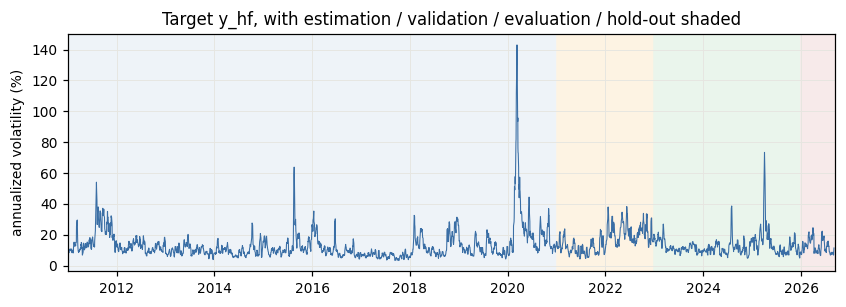

In [5]:
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(D.index, D["y_hf"] * 100, lw=0.7, color="#3a6ea5")
for a, b, c in [("2011-01-04", "2020-12-31", "#eef3f8"), ("2021-01-01", "2022-12-31", "#fdf3e3"),
                ("2023-01-01", "2025-12-31", "#eaf5ec"), ("2026-01-01", "2026-09-14", "#f7eaea")]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, zorder=0)
ax.set_ylabel("annualized volatility (%)")
ax.set_title("Target y_hf, with estimation / validation / evaluation / hold-out shaded")
ax.set_xlim(D.index.min(), D.index.max())
plt.show()

<!-- mono -->
## [F2] 預測變數區塊與共線性 / Predictor blocks and collinearity

- 對應程式 source: `build_dataset.py, groups.json`
- 文獻 reference: Patton and Sheppard (2015); Corsi (2009)
- 先備節點 prerequisites: F1

---

<!-- bilingual -->
**中文**

### 原理

F1 只給了波動率自己的歷史。但波動率的可預測資訊不只來自它自己：下跌與跳躍、選擇權市場的前瞻定價、利率與跨資產報酬，都可能有增額內容。問題是這些變數彼此高度相關，直接全部丟進迴歸會讓係數不穩、符號亂跳——**這不是預測問題，是解釋問題**，但它會讓「哪個變數有用」的討論失去意義。

本研究把 18 個變數編成 7 個區塊，之後的分解與 Granger 檢定都以**區塊**為單位，而不是單一變數。

### 公式

共線性用變異數膨脹因子 (variance inflation factor) 衡量。把第 $j$ 個變數對其餘所有變數迴歸，得到判定係數 $R_j^2$，則

$$VIF_j = \frac{1}{1 - R_j^2}$$

VIF 為 10 大致對應 $R_j^2 = 0.9$。

### 演算法

兩個隱含波動率指數 VIX 與 VIX9D 在對數變異數形式下幾乎共線。本研究不是刪掉其中一個，而是做**線性重新參數化**：以水準 $\log VIX^2$ 與斜率 $\log(VIX9D / VIX)$ 取代兩個變異數。因為是線性變換，迴歸的配適值完全不變，但個別係數變得可解釋、VIF 大幅下降。

### 程式設計邏輯

下面同時做三件事：算兩種參數化的 VIF、驗證「配適值完全相同」這個主張、並用同一個指標檢查第二標的所用的相對報酬：換成原始報酬時，共線性會推高到什麼程度。注意 VIF 要在**哪一個設計矩陣**下計算會影響數值——這一點稿件沒有寫明，重現時必須自己找出來，下一格會示範這個過程。

---

**English**

### Principle

F1 supplies only volatility's own history. Predictable information comes from elsewhere too: downside moves and jumps, the forward-looking prices in the option market, interest rates and cross-asset returns. The difficulty is that these variables are correlated with one another, so entering them all makes coefficients unstable and signs flip. **That is an interpretation problem rather than a forecasting one**, but it makes any discussion of which variable matters meaningless.

This study groups 18 variables into 7 blocks, and both the decomposition and the Granger tests later work at **block** level rather than variable level.

### Formulas

Collinearity is measured by the variance inflation factor. Regress variable $j$ on all the others, obtain $R_j^2$, then

$$VIF_j = \frac{1}{1 - R_j^2}$$

A VIF of 10 corresponds roughly to $R_j^2 = 0.9$.

### Algorithm

The two implied volatility indices, VIX and VIX9D, are nearly collinear in log variance form. Rather than dropping one, the study applies a **linear reparameterization**: the level $\log VIX^2$ and the slope $\log(VIX9D / VIX)$ replace the two variances. Because the transformation is linear the fitted values are unchanged, but the individual coefficients become interpretable and the inflation factors fall sharply.

### Program logic

The cell below does three things at once: computes the inflation factors under both parameterizations, verifies the claim that fitted values are identical, and checks whether the relative return used for the second asset really is less correlated than the raw return. Note that **which design matrix** the factors are computed in changes the numbers; the manuscript does not say which, so the reproduction has to find out, as the next cell shows.

In [6]:
HAR = GROUPS["G1 歷史已實現變異"]
OPT = GROUPS["G3 選擇權前瞻"]
FEATS = [c for g in GROUPS.values() for c in g]
EST = (D.index >= "2011-01-04") & (D.index <= "2020-12-31")

print("blocks and variables")
for name, cols in GROUPS.items():
    print(f"  {name:22s} {cols}")
print(f"\ntotal predictors: {len(FEATS)}")


def vif(X, j):
    """VIF from the auxiliary regression of column j on the rest; written out rather than
    imported so the formula and the code sit next to each other."""
    y_j = X[:, j]
    Z = np.c_[np.ones(len(X)), np.delete(X, j, axis=1)]
    b = np.linalg.lstsq(Z, y_j, rcond=None)[0]
    resid = y_j - Z @ b
    r2 = 1 - (resid @ resid) / (((y_j - y_j.mean()) ** 2).sum())
    return 1 / (1 - r2)


def both_parameterizations(cols, mask):
    sub = D[mask][cols].dropna()
    X_ls = sub.values                                   # level and slope (the paper's choice)
    i_lv, i_sl = cols.index("lvix"), cols.index("vix_slope")
    X_vv = X_ls.copy()
    X_vv[:, i_sl] = X_ls[:, i_lv] + 2 * X_ls[:, i_sl]   # log VIX9D^2 = log VIX^2 + 2 log(VIX9D/VIX)
    return (vif(X_ls, i_lv), vif(X_ls, i_sl), vif(X_vv, i_lv), vif(X_vv, i_sl), len(sub))

blocks and variables
  G1 歷史已實現變異             ['lrv_d', 'lrv_w', 'lrv_m']
  G2 下跌與跳躍               ['lrs_neg', 'jump']
  G3 選擇權前瞻               ['lvix', 'vix_slope']
  G4 報酬                  ['r_cc', 'r_on', 'r_w', 'r_m']
  G5 利率                  ['d_y10', 'term']
  G6 美元與跨資產              ['r_dxy', 'r_qqq', 'r_tlt', 'r_gld']
  G7 交易量                 ['vol_rel']

total predictors: 18


<!-- bilingual -->
**中文**

### 找出稿件數字是在哪個設計下算的

稿件報告的 VIF 是 6.3 與 1.6（水準＋斜率）、26.9 與 24.6（兩個變異數），但沒有說是在哪一個迴歸設計、哪一段樣本上算的。重現時不可以調參數去湊，正確做法是把合理的候選設定全部列出來，看哪一個完全吻合。

---

**English**

### Finding out which design the manuscript's numbers come from

The manuscript reports inflation factors of 6.3 and 1.6 (level and slope) and 26.9 and 24.6 (two variances), without saying in which regression design or over which sample. The reproduction must not tune until it matches; the right move is to enumerate the defensible candidates and see which one agrees exactly.

In [7]:
ALL = (D.index >= "2011-01-04") & (D.index <= "2025-12-31")
cands = {
    "all 18 predictors, estimation sample": (FEATS, EST),
    "all 18 predictors, 2011-2025": (FEATS, ALL),
    "HAR + option block, estimation sample": (HAR + OPT, EST),
    "HAR + option block, 2011-2025": (HAR + OPT, ALL),
}
rows = []
for lab, (cols, mask) in cands.items():
    lv, sl, vv1, vv2, n = both_parameterizations(cols, mask)
    rows.append(dict(design=lab, n=n, VIF_level=lv, VIF_slope=sl, VIF_logVIX2=vv1, VIF_logVIX9D2=vv2))
tab = pd.DataFrame(rows).set_index("design").round(1)
print(tab.to_string())
print("\nmanuscript: level 6.3, slope 1.6, logVIX2 26.9, logVIX9D2 24.6")

match = tab.loc["HAR + option block, estimation sample"]
reg.check("VIF_level", match.VIF_level, note="design inferred: HAR plus option block, estimation sample")
reg.check("VIF_slope", match.VIF_slope, note="design inferred: same specification as VIF_level")
reg.check("VIF_vix_raw", match.VIF_logVIX2, note="design inferred: same specification as VIF_level")
reg.check("VIF_vix9d_raw", match.VIF_logVIX9D2, note="design inferred: same specification as VIF_level")

                                          n  VIF_level  VIF_slope  VIF_logVIX2  VIF_logVIX9D2
design                                                                                       
all 18 predictors, estimation sample   2516        7.4        1.9         29.1           29.0
all 18 predictors, 2011-2025           3771        5.9        1.7         20.9           23.4
HAR + option block, estimation sample  2516        6.3        1.6         26.9           24.6
HAR + option block, 2011-2025          3771        4.9        1.5         20.2           20.3

manuscript: level 6.3, slope 1.6, logVIX2 26.9, logVIX9D2 24.6
OK VIF_level              manuscript=6.3          notebook=6.3            reproduced_note / 重現（附註）  (design inferred: HAR plus option block, estimation sample)
OK VIF_slope              manuscript=1.6          notebook=1.6            reproduced_note / 重現（附註）  (design inferred: same specification as VIF_level)
OK VIF_vix_raw            manuscript=26.9         notebook=26

In [8]:
# The reparameterization is linear, so the fitted values must be identical to machine precision.
sub = D[EST][HAR + OPT + ["y_hf"]].dropna()
X_ls = sub[HAR + OPT].values
i_lv, i_sl = (HAR + OPT).index("lvix"), (HAR + OPT).index("vix_slope")
X_vv = X_ls.copy()
X_vv[:, i_sl] = X_ls[:, i_lv] + 2 * X_ls[:, i_sl]
y_log = np.log(sub["y_hf"].values)


def fitted(X):
    Z = np.c_[np.ones(len(X)), X]
    return Z @ np.linalg.lstsq(Z, y_log, rcond=None)[0]


diff = np.abs(fitted(X_ls) - fitted(X_vv)).max()
print(f"max |fitted difference| between the two parameterizations = {diff:.2e}")
reg.check_text("reparam_identical", diff < 1e-10, f"max gap {diff:.1e}")

corr_iv = np.corrcoef(X_vv[:, i_lv], X_vv[:, i_sl])[0, 1]
print(f"corr(log VIX^2, log VIX9D^2) on the estimation sample = {corr_iv:.3f}")
reg.check("corr_vix_vix9d", corr_iv)

# The same argument for the second application, again in inflation factors rather than
# correlations: the design is the daily-only predictor set of Section 8.
dS = pd.read_csv(DATA / "daily_SPY.csv", parse_dates=["Date"]).set_index("Date")
m = (dS.index >= "2011-01-04") & (dS.index <= "2020-12-31")
daily_cols = [c for c in dS.columns if c not in ("y", "ret_pct")]
sub2 = dS[m][daily_cols].dropna()
j_cross, j_own = daily_cols.index("r_rel"), daily_cols.index("r_cc")
X_rel = sub2.values
qqq = D["r_qqq"].reindex(sub2.index).values
fin = np.isfinite(qqq)
X_raw = X_rel[fin].copy()
X_raw[:, j_cross] = qqq[fin]                      # swap the relative return for the raw one
print(f"cross-asset variable as the relative return: VIF {vif(X_rel, j_cross):.2f}, "
      f"own return {vif(X_rel, j_own):.2f}")
print(f"cross-asset variable as the raw return     : VIF {vif(X_raw, j_cross):.2f}, "
      f"own return {vif(X_raw, j_own):.2f}")
print("manuscript: 1.1 and 2.8 against 7.5 and 10.1")
reg.check("VIF_rel", vif(X_rel, j_cross))
reg.check("VIF_own_rel", vif(X_rel, j_own))
reg.check("VIF_raw_qqq", vif(X_raw, j_cross))
reg.check("VIF_own_raw", vif(X_raw, j_own))

max |fitted difference| between the two parameterizations = 1.55e-15
OK reparam_identical      manuscript=TRUE         notebook=True           reproduced / 重現  (max gap 1.6e-15)
corr(log VIX^2, log VIX9D^2) on the estimation sample = 0.975
OK corr_vix_vix9d         manuscript=0.975        notebook=0.975          reproduced / 重現
cross-asset variable as the relative return: VIF 1.07, own return 2.77
cross-asset variable as the raw return     : VIF 7.46, own return 10.06
manuscript: 1.1 and 2.8 against 7.5 and 10.1
OK VIF_rel                manuscript=1.1          notebook=1.1            reproduced / 重現
OK VIF_own_rel            manuscript=2.8          notebook=2.8            reproduced / 重現
OK VIF_raw_qqq            manuscript=7.5          notebook=7.5            reproduced / 重現
OK VIF_own_raw            manuscript=10.1         notebook=10.1           reproduced / 重現


<!-- mono -->
## [F3] 樣本外評估協定 / Out-of-sample protocol

- 對應程式 source: `ladder.py (windows), Section 3.6`
- 文獻 reference: Chassot and Audrino (2026); Feng and Zhang (2025)
- 先備節點 prerequisites: F1

---

<!-- bilingual -->
**中文**

### 原理

F1 與 F2 給了資料，但「模型有多好」這個問題在樣本內沒有意義：參數越多、樣本內越好看。必須有一個**在估計時看不到評估期**的協定。

多日目標帶來一個容易漏掉的陷阱：第 $t$ 天的目標用到第 $t+1$ 到 $t+5$ 天的資料。如果估計樣本一路延伸到評估期前一天，最後五個訓練目標就已經含有評估期的資訊——**訓練集偷看了測試集**。本研究的做法是把估計樣本的最後五個觀測整段丟掉（purging）。

### 公式

設評估年為 $Y$，估計樣本為 $\lbrace t: t_0 \le t \le T_{Y-1} - 5 \rbrace$，其中 $T_{Y-1}$ 是 $Y-1$ 年的最後一個交易日。每年重估一次，視窗向前展開 (expanding)。

### 演算法

1. 對每個評估年 $Y \in \lbrace 2023, 2024, 2025 \rbrace$：估計樣本為 2011-01-04 至 $Y-1$ 年底，去尾五日。
2. 在估計樣本上估計所有參數，包含標準化常數。
3. 對 $Y$ 年逐日產生預測，不再更新參數。
4. 把三年的預測接起來，得到 752 天的評估序列。

**超參數**只在第一個視窗的驗證區間（2021–2022）選一次，之後固定；保留樣本（2026）在設計定案前就先封存，整篇論文只用一次。

### 程式設計邏輯

`windows()` 把這個協定寫成一個產生器，所有模型共用它——這是讓「資訊集合對等」成立的前提：**同樣的視窗、同樣的樣本、同樣的重估頻率**，差別只在看得到哪些變數。

---

**English**

### Principle

F1 and F2 supply the data, but asking how good a model is has no meaning in sample: more parameters always look better there. A protocol is needed in which **estimation cannot see the evaluation period**.

A multi-day target brings a trap that is easy to miss. The target at day $t$ uses days $t+1$ to $t+5$. If the estimation sample runs to the day before the evaluation period, its last five targets already contain evaluation-period information — **the training set has seen the test set**. The study drops the last five observations of each estimation sample (purging).

### Formulas

For evaluation year $Y$ the estimation sample is $\lbrace t: t_0 \le t \le T_{Y-1} - 5 \rbrace$, where $T_{Y-1}$ is the last trading day of year $Y-1$. The model is re-estimated once a year on an expanding window.

### Algorithm

1. For each evaluation year $Y \in \lbrace 2023, 2024, 2025 \rbrace$: estimate on 2011-01-04 to the end of $Y-1$, less the final five days.
2. Estimate every parameter, including standardization constants, on that sample only.
3. Forecast each day of $Y$ without updating parameters.
4. Concatenate the three years into the 752-day evaluation series.

**Hyperparameters** are chosen once, on the validation block of the first window (2021-2022), then held fixed; the hold-out year (2026) is sealed before the design is frozen and used once.

### Program logic

`windows()` encodes the protocol as a generator shared by every model. That sharing is what makes information-set parity possible: **the same windows, the same samples, the same re-estimation frequency**, differing only in which variables each model may see.

In [9]:
TEST_YEARS = (2023, 2024, 2025)
START = "2011-01-04"


def windows(years=TEST_YEARS, start=START):
    """Yield (year, train_idx, test_idx). The [:-5] slice is the purge: the last five
    estimation targets would otherwise overlap the evaluation period."""
    for Y in years:
        te = np.where((D.index >= f"{Y}-01-01") & (D.index <= f"{Y}-12-31"))[0]
        tr = np.where((D.index >= start) & (D.index <= f"{Y - 1}-12-31"))[0][:-5]
        yield Y, tr, te


split = {
    "Estimation 2011-2020": int(((D.index >= "2011-01-04") & (D.index <= "2020-12-31")).sum()),
    "Validation 2021-2022": int(((D.index >= "2021-01-01") & (D.index <= "2022-12-31")).sum()),
    "Evaluation 2023-2025": int(((D.index >= "2023-01-01") & (D.index <= "2025-12-31")).sum()),
    "Hold-out 2026": int((D.index >= "2026-01-01").sum()),
}
for k, v in split.items():
    print(f"  {k:24s} {v:5d}")

reg.check_count("N_est", split["Estimation 2011-2020"])
reg.check_count("N_val", split["Validation 2021-2022"])
reg.check_count("N_eval", split["Evaluation 2023-2025"])
reg.check_count("N_holdout", split["Hold-out 2026"])

for Y, tr, te in windows():
    print(f"  {Y}: train {len(tr):5d} days ending {D.index[tr[-1]].date()}  |  test {len(te)} days")
print("\npurge check: the last training target must not overlap the first test day")
for Y, tr, te in windows():
    overlap = D.index[tr[-1]] + pd.Timedelta(days=0)
    print(f"  {Y}: last train index {D.index[tr[-1]].date()}, first test {D.index[te[0]].date()}, "
          f"gap {(D.index[te[0]] - D.index[tr[-1]]).days} calendar days")

  Estimation 2011-2020      2516
  Validation 2021-2022       503
  Evaluation 2023-2025       752
  Hold-out 2026              175
OK N_est                  manuscript=2516         notebook=2516           reproduced / 重現
OK N_val                  manuscript=503          notebook=503            reproduced / 重現
OK N_eval                 manuscript=752          notebook=752            reproduced / 重現
OK N_holdout              manuscript=175          notebook=175            reproduced / 重現


  2023: train  3014 days ending 2022-12-22  |  test 250 days
  2024: train  3264 days ending 2023-12-21  |  test 252 days
  2025: train  3516 days ending 2024-12-23  |  test 250 days

purge check: the last training target must not overlap the first test day
  2023: last train index 2022-12-22, first test 2023-01-03, gap 12 calendar days
  2024: last train index 2023-12-21, first test 2024-01-02, gap 12 calendar days
  2025: last train index 2024-12-23, first test 2025-01-02, gap 10 calendar days


<!-- mono -->
## [C1] 代理變數穩健損失函數 / Proxy-robust loss functions

- 對應程式 source: `evaluate.py (mse_var, qlike)`
- 文獻 reference: Patton (2011); Taylor (2026)
- 先備節點 prerequisites: F1

---

<!-- bilingual -->
**中文**

### 原理

F1 建好了目標，但目標只是**代理變數**：真正的潛在波動率沒人看得到。這帶來一個不明顯的危險——用錯損失函數時，代理變數的雜訊會讓**排序本身**偏掉，也就是說，比較的結果可能是雜訊造成的，而不是模型優劣造成的。

Patton (2011) 刻畫了一族損失函數，在這族之內，即使用有雜訊的代理變數，期望損失的排序仍與用真實波動率時相同。平方誤差（變異數尺度）與 QLIKE 是其中最常用的兩個。本研究兩個都報，主要用 QLIKE。

### 公式

以 $\sigma^2$ 表示代理的變異數、$\hat{\sigma}^2$ 表示預測，QLIKE 為

$$L(\sigma^2, \hat{\sigma}^2) = \frac{\sigma^2}{\hat{\sigma}^2} - \log \frac{\sigma^2}{\hat{\sigma}^2} - 1$$

它在 $\hat{\sigma}^2 = \sigma^2$ 時為 0，且對**低估**的懲罰重於高估——這對風險管理是正確的方向。變異數尺度的平方誤差則是 $(\sigma^2 - \hat{\sigma}^2)^2$，對高波動日的權重大得多。

### 演算法

1. 把預測與實現值都換算到**同一個尺度**（這裡是年化波動率，平方後成為變異數）。
2. 逐日計算損失，取平均。
3. 兩個損失函數都算：若兩者給出的排序不同，那本身就是結果的一部分。

### 程式設計邏輯

損失函數寫成純函數、接受向量，後面每一個檢定都重複使用它們。注意 `mse_var` 乘了 $10^8$ 只是為了讓數字好讀——**縮放不影響任何檢定**，但會影響表格的可讀性，所以把縮放寫在函數裡、而不是散落在輸出格式中。

---

**English**

### Principle

F1 built the target, but the target is only a **proxy**: latent volatility is unobserved. That creates a danger which is not obvious — under the wrong loss function, proxy noise can distort **the ranking itself**, so that a comparison reflects noise rather than forecast quality.

Patton (2011) characterised a family of loss functions under which the expected-loss ranking with a noisy proxy is the same as with true volatility. Squared error in variance units and QLIKE are its two best-known members. This study reports both and leads with QLIKE.

### Formulas

With $\sigma^2$ the proxy variance and $\hat{\sigma}^2$ the forecast, QLIKE is

$$L(\sigma^2, \hat{\sigma}^2) = \frac{\sigma^2}{\hat{\sigma}^2} - \log \frac{\sigma^2}{\hat{\sigma}^2} - 1$$

It is zero when $\hat{\sigma}^2 = \sigma^2$ and penalises **under-prediction** more heavily than over-prediction, which is the right direction for risk management. Squared error in variance units, $(\sigma^2 - \hat{\sigma}^2)^2$, puts far more weight on high-volatility days.

### Algorithm

1. Put forecast and realisation on the **same scale** (here annualized volatility, squared into variance).
2. Evaluate the loss day by day and average.
3. Compute both losses: if they rank models differently, that disagreement is itself a result.

### Program logic

The losses are plain functions over vectors, reused by every test that follows. The factor of $10^8$ in `mse_var` only makes the numbers readable — **scaling changes no test** — and it lives inside the function rather than in print formatting so that every caller shares it.

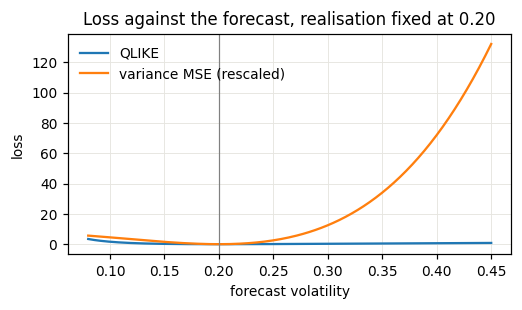

QLIKE at half the truth : 1.614
QLIKE at twice the truth: 0.636


In [10]:
A = 252


def qlike(y, f):
    """QLIKE on variances built from volatility inputs y and f."""
    ratio = (y ** 2) / (f ** 2)
    return ratio - np.log(ratio) - 1


def mse_var(y, f):
    """Squared error in variance units, scaled by 1e8 for readability only."""
    return ((y ** 2 - f ** 2) ** 2) * 1e8


def rmse_vol(y, f):
    return np.sqrt(np.mean(((f - y) * 100) ** 2))


def mae_vol(y, f):
    return np.mean(np.abs((f - y) * 100))


# Why QLIKE is asymmetric: hold the realisation fixed and move the forecast.
sigma = 0.20
grid = np.linspace(0.08, 0.45, 200)
fig, ax = plt.subplots(figsize=(5.2, 2.6))
ax.plot(grid, qlike(np.full_like(grid, sigma), grid), label="QLIKE")
ax.plot(grid, mse_var(np.full_like(grid, sigma), grid) / 2e4, label="variance MSE (rescaled)")
ax.axvline(sigma, color="grey", lw=0.8)
ax.set_xlabel("forecast volatility")
ax.set_ylabel("loss")
ax.set_title("Loss against the forecast, realisation fixed at 0.20")
ax.legend()
plt.show()
print("QLIKE at half the truth :", f"{qlike(sigma, sigma / 2):.3f}")
print("QLIKE at twice the truth:", f"{qlike(sigma, sigma * 2):.3f}")

In [11]:
# The evaluation sample and the stored forecast series used throughout the notebook.
P = pd.read_csv(PRED / "pred_main_SPY.csv")
P.columns = [c.lstrip("\ufeff") for c in P.columns]


def forecasts(target):
    """Wide matrix of forecasts plus the realised target, for one target definition.

    The explicit filter on `target` matters: the file stacks y_hf and y_cc, and a pivot
    without it silently averages two different targets (see unit D2)."""
    g = P[P["target"] == target]
    W = g.pivot_table(index="date", columns="model", values="forecast")
    W.index = pd.to_datetime(W.index)
    y = g.groupby("date")["actual"].first()
    y.index = pd.to_datetime(y.index)
    assert len(W) == 752, f"expected 752 evaluation days, got {len(W)}"
    assert g.groupby(["date", "model"]).size().max() == 1, "duplicated (date, model) rows"
    return W, y


W, Y = forecasts("y_hf")
WB, YB = forecasts("y_cc")
MODELS = ["L0 Naive", "L1 GARCH(1,1)", "L1 GJR-GARCH", "L2 HAR-RV",
          "L3 HAR-RV-X (opt only)", "L3 HAR-RV-X (full)", "L3 GARCH-X", "L4 Transformer"]

tab = pd.DataFrame({
    "A: MAE": [mae_vol(Y, W[m]) for m in MODELS],
    "A: RMSE": [rmse_vol(Y, W[m]) for m in MODELS],
    "A: QLIKE": [qlike(Y, W[m]).mean() for m in MODELS],
    "B: QLIKE": [qlike(YB, WB[m]).mean() for m in MODELS],
}, index=MODELS)
print(tab.round(4).to_string())

reg.check("T51_qlike_L0", tab.loc["L0 Naive", "A: QLIKE"])
reg.check("T51_qlike_trf", tab.loc["L4 Transformer", "A: QLIKE"],
          note="computed from the stored ten-seed ensemble forecast; the network is not retrained here")
reg.check("T51_rmse_trf", tab.loc["L4 Transformer", "A: RMSE"], note="same")
reg.check("T51B_qlike_trf", tab.loc["L4 Transformer", "B: QLIKE"], note="same")
reg.check_text("T51_best_model",
               tab["A: QLIKE"].idxmin() == "L3 HAR-RV-X (full)" and tab["B: QLIKE"].idxmin() == "L3 HAR-RV-X (full)",
               "lowest QLIKE at both targets")
reg.check_text("T51_nonmonotone",
               tab.loc["L2 HAR-RV", "A: QLIKE"] > tab.loc["L1 GJR-GARCH", "A: QLIKE"],
               "HAR-RV above GJR-GARCH")

                        A: MAE  A: RMSE  A: QLIKE  B: QLIKE
L0 Naive                3.7586   6.7685    0.3176    0.8269
L1 GARCH(1,1)           3.9173   6.4909    0.2340    0.3888
L1 GJR-GARCH            3.5298   5.6802    0.1998    0.3446
L2 HAR-RV               3.2044   5.6221    0.2318    0.3895
L3 HAR-RV-X (opt only)  2.8402   5.1519    0.1928    0.3227
L3 HAR-RV-X (full)      2.9436   5.1485    0.1835    0.3108
L3 GARCH-X              3.5433   5.6927    0.2003    0.3454
L4 Transformer          3.2602   5.3614    0.2079    0.3122
OK T51_qlike_L0           manuscript=0.3176       notebook=0.3176         reproduced / 重現
OK T51_qlike_trf          manuscript=0.2079       notebook=0.2079         reproduced_note / 重現（附註）  (computed from the stored ten-seed ensemble forecast; the network is not retrained here)
OK T51_rmse_trf           manuscript=5.36         notebook=5.36           reproduced_note / 重現（附註）  (same)
OK T51B_qlike_trf         manuscript=0.3122       notebook=0.3122         

<!-- mono -->
## [C2] HAR-RV 與對數尺度迴歸 / HAR-RV and regression on the log variance

- 對應程式 source: `ladder.py (linreg)`
- 文獻 reference: Corsi (2009); Taylor (2026)
- 先備節點 prerequisites: F1, F3

---

<!-- bilingual -->
**中文**

### 原理

C1 給了評分方式，但還沒有模型。波動率有長記憶：今天的波動與一個月前的波動仍然相關。完整的長記憶模型估計困難，Corsi (2009) 的異質自迴歸 (heterogeneous autoregressive, HAR) 用三個變數——昨日、過去五日平均、過去 22 日平均——就重現了長記憶的衰減形狀，而且是線性迴歸，幾百筆資料就估得動。

### 公式

以對數年化變異數為被解釋變數：

$$\log RV_{t+1:t+5} = \beta_0 + \beta_d \log RV_t + \beta_w \log RV_{t-4:t} + \beta_m \log RV_{t-21:t} + \varepsilon_{t}$$

預測變異數時必須轉回原尺度。若 $\varepsilon$ 近似常態且變異數為 $s^2$，則

$$\widehat{RV} = \exp(\hat{y} + s^2 / 2)$$

這個 $s^2/2$ 是 Jensen 修正：少了它，預測會系統性偏低。

### 演算法

1. 取對數、用最小平方法估計；殘差變異數 $s^2$ 由估計樣本算出。
2. 以 $\exp(\hat{y} + s^2/2)$ 轉回變異數，開根號得到波動率。
3. 加入外生變數時**只改設計矩陣的欄位**，其餘一字不動——這是 K1 資訊集合對等的實作方式。

### 程式設計邏輯

下面刻意用 `np.linalg.lstsq` 而不是套件的迴歸物件：教學上要看見「係數 = 解正規方程式」這件事，而且它讓同一行程式服務三種資訊集合。

**一個誠實的限制**：Taylor (2026) 指出，用對數模型建構、卻用相對損失（如 QLIKE）評估時，正確的轉換修正應同時取決於損失函數與誤差分布。這裡用的 $s^2/2$ 是高斯平方誤差下的修正，對 QLIKE 並非最適；但它對每一個以對數估計的階梯一視同仁，不偏袒比較的任一方。

---

**English**

### Principle

C1 supplied the scoring rule but no model. Volatility has long memory: today's level is still correlated with a month ago. Estimating a full long-memory model is awkward, and the heterogeneous autoregressive (HAR) model of Corsi (2009) reproduces the decay with three regressors — yesterday, the past five days, the past 22 days — in a linear regression that a few hundred observations can estimate.

### Formulas

With the log annualized variance as the dependent variable:

$$\log RV_{t+1:t+5} = \beta_0 + \beta_d \log RV_t + \beta_w \log RV_{t-4:t} + \beta_m \log RV_{t-21:t} + \varepsilon_{t}$$

Forecasting a variance requires transforming back. If $\varepsilon$ is approximately normal with variance $s^2$, then

$$\widehat{RV} = \exp(\hat{y} + s^2 / 2)$$

The $s^2/2$ is the Jensen correction; without it the forecast is systematically too low.

### Algorithm

1. Take logs, estimate by least squares, compute the residual variance $s^2$ on the estimation sample.
2. Transform back with $\exp(\hat{y} + s^2/2)$ and take the square root for volatility.
3. Adding exogenous variables **changes only the columns of the design matrix**, nothing else — this is how information-set parity (K1) is implemented.

### Program logic

`np.linalg.lstsq` is used deliberately rather than a regression object: the reader should see that the coefficients solve the normal equations, and the same line then serves three different information sets.

**An honest limitation.** Taylor (2026) shows that when a forecast is built from a log model and evaluated with a relative loss such as QLIKE, the back-transformation should carry an adjustment depending on both the loss and the error distribution. The $s^2/2$ used here is the Gaussian squared-error correction, which is not loss-optimal for QLIKE; it applies identically to every rung estimated in logs, so it does not favour either side of the comparison.

In [12]:
def linreg(target, cols, tr, te):
    """OLS on the log target, back-transformed with the Jensen correction.

    Written from scratch (normal equations via lstsq) so the formula above and the code
    sit side by side; the estimation sample is passed in, never inferred here."""
    X = np.c_[np.ones(len(D)), D[cols].values]
    y_log = np.log(D[target].values)
    ok = tr[np.isfinite(y_log[tr])]
    b = np.linalg.lstsq(X[ok], y_log[ok], rcond=None)[0]
    s2 = np.var(y_log[ok] - X[ok] @ b)
    return np.exp(X[te] @ b + 0.5 * s2)


def ladder_linear(target, cols):
    """Run the protocol of F3 for one information set and stitch the years together."""
    parts = [pd.Series(linreg(target, cols, tr, te), D.index[te]) for _, tr, te in windows()]
    return pd.concat(parts)


refit = {}
for name, cols in [("HAR-RV", HAR), ("HAR-RV-X (opt only)", HAR + OPT), ("HAR-RV-X (full)", FEATS)]:
    f = ladder_linear("y_hf", cols)
    y = D["y_hf"].reindex(f.index)
    refit[name] = dict(MAE=mae_vol(y, f), RMSE=rmse_vol(y, f), QLIKE=qlike(y, f).mean())
    refit[name + " | B"] = dict(QLIKE=qlike(D["y_cc"].reindex(f.index), ladder_linear("y_cc", cols)).mean())

print(pd.DataFrame(refit).T.round(4).to_string())
print("\nmanuscript Table 5.1: HAR-RV 0.2318 | option only 0.1928 | full 0.1835")

reg.check("T51_qlike_har", refit["HAR-RV"]["QLIKE"])
reg.check("T51_qlike_harx_opt", refit["HAR-RV-X (opt only)"]["QLIKE"])
reg.check("T51_qlike_harx_full", refit["HAR-RV-X (full)"]["QLIKE"])
reg.check("T51_rmse_harx_full", refit["HAR-RV-X (full)"]["RMSE"])
reg.check("T51_mae_harx_opt", refit["HAR-RV-X (opt only)"]["MAE"])
reg.check("T51B_qlike_harx_full", refit["HAR-RV-X (full) | B"]["QLIKE"])

                            MAE    RMSE   QLIKE
HAR-RV                   3.2044  5.6221  0.2318
HAR-RV | B                  NaN     NaN  0.3895
HAR-RV-X (opt only)      2.8402  5.1519  0.1928
HAR-RV-X (opt only) | B     NaN     NaN  0.3227
HAR-RV-X (full)          2.9436  5.1485  0.1835
HAR-RV-X (full) | B         NaN     NaN  0.3108

manuscript Table 5.1: HAR-RV 0.2318 | option only 0.1928 | full 0.1835
OK T51_qlike_har          manuscript=0.2318       notebook=0.2318         reproduced / 重現
OK T51_qlike_harx_opt     manuscript=0.1928       notebook=0.1928         reproduced / 重現
OK T51_qlike_harx_full    manuscript=0.1835       notebook=0.1835         reproduced / 重現
OK T51_rmse_harx_full     manuscript=5.15         notebook=5.15           reproduced / 重現
OK T51_mae_harx_opt       manuscript=2.84         notebook=2.84           reproduced / 重現
OK T51B_qlike_harx_full   manuscript=0.3108       notebook=0.3108         reproduced / 重現


In [13]:
# What the coefficients look like, and why the Jensen correction is not cosmetic.
tr_last = list(windows())[-1][1]
X = np.c_[np.ones(len(D)), D[HAR].values]
y_log = np.log(D["y_hf"].values)
ok = tr_last[np.isfinite(y_log[tr_last])]
b = np.linalg.lstsq(X[ok], y_log[ok], rcond=None)[0]
s2 = np.var(y_log[ok] - X[ok] @ b)
print("HAR coefficients on the 2025 window:",
      dict(zip(["const"] + HAR, np.round(b, 4))), f"| s2 = {s2:.4f}")

te_all = np.where((D.index >= "2023-01-01") & (D.index <= "2025-12-31"))[0]
with_corr = ladder_linear("y_hf", HAR)
without = np.exp(np.c_[np.ones(len(D)), D[HAR].values][te_all] @ b)      # no s2/2, last window's b
print(f"QLIKE with the Jensen correction   : {qlike(D['y_hf'].reindex(with_corr.index), with_corr).mean():.4f}")
print(f"QLIKE without it (same window's b) : "
      f"{qlike(D['y_hf'].values[te_all], without).mean():.4f}   <- biased low, worse loss")

HAR coefficients on the 2025 window: {'const': np.float64(-0.3672), 'lrv_d': np.float64(0.138), 'lrv_w': np.float64(0.14), 'lrv_m': np.float64(0.1346)} | s2 = 0.0980
QLIKE with the Jensen correction   : 0.2318
QLIKE without it (same window's b) : 0.2493   <- biased low, worse loss


<!-- mono -->
## [C3] GARCH 與 GJR-GARCH / GARCH and GJR-GARCH with Student-t errors

- 對應程式 source: `ladder.py (garch)`
- 文獻 reference: Engle (1982); Glosten et al. (1993); Hansen and Lunde (2005)
- 先備節點 prerequisites: F1, F3

---

<!-- bilingual -->
**中文**

### 原理

C2 的 HAR 需要日內資料才能建出 $RV$。但有一整類模型**只用日報酬**就能描述波動叢聚，那就是 GARCH。它在本研究裡是資訊階梯的第一層：代表「只有日報酬」這個資訊集合。

GARCH(1,1) 對稱地看待正負報酬，但股價下跌後的波動通常高於同幅度上漲之後——槓桿效果。GJR-GARCH 加一個只在負報酬時啟動的項來捕捉它。Hansen and Lunde (2005) 的大規模比較發現沒有模型顯著勝過簡單的 GARCH(1,1)；本研究的結果顯示**非對稱版本是很難打敗的基準**。

### 公式

$$h_t = \omega + (\alpha + \gamma I[\varepsilon_{t-1} < 0]) \varepsilon_{t-1}^2 + \beta h_{t-1}$$

$\gamma = 0$ 時退化為 GARCH(1,1)。持續性為 $\alpha + \gamma/2 + \beta$，必須小於 1 才定態。誤差用 Student-t 分布以容納厚尾。

多步預測由遞迴得到，再把五天的條件變異數相加、年化、開根號，換算成與目標同尺度的波動率。

### 演算法

1. 以最大概似估計 $(\omega, \alpha, \gamma, \beta, \nu)$。
2. 用 `last_obs` 告訴套件哪一天之後不得使用——這是把 F3 的協定落實到套件呼叫上。
3. 對評估期每一天做 5 步預測，加總五天的變異數。

### 程式設計邏輯

這裡用 `arch` 套件而非自己寫 MLE，因為這是標準估計；真正需要從零實作的是 K3 的 GARCH-X（套件沒有那個規格）。報酬以**百分比**輸入是 `arch` 的慣例，數值條件較好；輸出要除以 100 才回到小數尺度，這種單位轉換是最常見的錯誤來源之一。

---

**English**

### Principle

The HAR model of C2 needs intraday data to build $RV$. An entire model class describes volatility clustering from **daily returns alone**: GARCH. In this study it is the first rung of the ladder, representing the information set that contains only daily returns.

GARCH(1,1) treats positive and negative returns symmetrically, yet volatility after a fall is typically higher than after a rise of the same size — the leverage effect. GJR-GARCH adds a term that switches on only for negative shocks. Hansen and Lunde (2005) found no specification that significantly beat a plain GARCH(1,1); in this study the asymmetric version is **a benchmark that is hard to beat**.

### Formulas

$$h_t = \omega + (\alpha + \gamma I[\varepsilon_{t-1} < 0]) \varepsilon_{t-1}^2 + \beta h_{t-1}$$

Setting $\gamma = 0$ gives GARCH(1,1). Persistence is $\alpha + \gamma/2 + \beta$ and must be below one for stationarity. The errors are Student-t to accommodate fat tails.

Multi-step forecasts follow from the recursion; the five conditional variances are summed, annualized and square-rooted onto the scale of the target.

### Algorithm

1. Estimate $(\omega, \alpha, \gamma, \beta, \nu)$ by maximum likelihood.
2. Pass `last_obs` so the library knows which day estimation may not see — this is how the F3 protocol reaches into the library call.
3. Produce five-step forecasts for every evaluation day and sum the five variances.

### Program logic

The `arch` package is used rather than a hand-written likelihood because this is a standard estimator; the specification that genuinely needs writing from scratch is the GARCH-X of K3, which no package provides. Returns enter in **percent**, the package's convention and better conditioned numerically; the output is divided by 100 to return to decimals. Unit conversions like this are among the most common sources of silent error.

In [14]:
from arch import arch_model


def garch_ladder(gjr):
    """Refit GARCH per evaluation year under exactly the protocol of F3."""
    parts, params = [], {}
    for Y, tr, te in windows():
        r = D["ret_pct"].iloc[tr[0]:te[-1] + 1]
        am = arch_model(r, mean="Constant", vol="GARCH", p=1, o=1 if gjr else 0, q=1, dist="t")
        res = am.fit(last_obs=D.index[tr[-1]] + pd.Timedelta(days=1), disp="off")
        fc = res.forecast(horizon=5, start=D.index[te[0]], reindex=False).variance.reindex(D.index[te])
        parts.append(pd.Series(np.sqrt(A / 5 * fc.sum(axis=1).values) / 100, D.index[te]))
        params[Y] = res.params.to_dict()
    return pd.concat(parts), params


f_g11, p_g11 = garch_ladder(False)
f_gjr, p_gjr = garch_ladder(True)
y = D["y_hf"].reindex(f_gjr.index)

print(f"GARCH(1,1) QLIKE {qlike(y, f_g11).mean():.4f}   manuscript 0.2340")
print(f"GJR-GARCH  QLIKE {qlike(y, f_gjr).mean():.4f}   manuscript 0.1998")
print("\nGJR parameters by window (note gamma > alpha: the asymmetry does the work)")
print(pd.DataFrame(p_gjr).T.round(4).to_string())
persist = {Y: p["alpha[1]"] + p.get("gamma[1]", 0) / 2 + p["beta[1]"] for Y, p in p_gjr.items()}
print("persistence:", {k: round(v, 4) for k, v in persist.items()})

reg.check("T51_qlike_g11", qlike(y, f_g11).mean())
reg.check("T51_qlike_gjr", qlike(y, f_gjr).mean())

GARCH(1,1) QLIKE 0.2340   manuscript 0.2340
GJR-GARCH  QLIKE 0.1998   manuscript 0.1998

GJR parameters by window (note gamma > alpha: the asymmetry does the work)
          mu   omega  alpha[1]  gamma[1]  beta[1]      nu
2023  0.0687  0.0258    0.0025    0.3077   0.8266  5.5619
2024  0.0697  0.0263    0.0000    0.2953   0.8317  5.9171
2025  0.0722  0.0272    0.0000    0.2887   0.8322  5.8662
persistence: {2023: 0.9829, 2024: 0.9793, 2025: 0.9766}
OK T51_qlike_g11          manuscript=0.2340       notebook=0.2340         reproduced / 重現
OK T51_qlike_gjr          manuscript=0.1998       notebook=0.1998         reproduced / 重現


<!-- mono -->
## [C4] Diebold-Mariano 檢定與 HLN 校正 / Diebold-Mariano with the HLN correction

- 對應程式 source: `evaluate.py (hac_var, dm_hln)`
- 文獻 reference: Diebold and Mariano (1995); Harvey et al. (1997)
- 先備節點 prerequisites: C1

---

<!-- bilingual -->
**中文**

### 原理

C1 到 C3 讓我們能算出兩個模型的平均損失誰比較小，但**小多少才算真的比較好**？直接比大小等於假設沒有抽樣誤差。DM 檢定把這個問題變成對損失差序列均值的檢定。

多日目標讓相鄰的損失差自動相關（第 $t$ 天與第 $t+1$ 天的目標共用四天），所以標準誤必須用 HAC 估計；小樣本下統計量還會偏大，HLN 校正處理這一點。

### 公式

令 $d_t = L(y_t, f_{1t}) - L(y_t, f_{2t})$，則

$$DM = \frac{\bar{d}}{\sqrt{\hat{V}(\bar{d})}}, \quad \hat{V}(\bar{d}) = \frac{1}{T}\left(\gamma_0 + 2\sum_{k=1}^{h-1} w_k \gamma_k\right)$$

其中 $w_k = 1 - k/(h+1)$ 為 Bartlett 權重、$\gamma_k$ 為自我共變異數。HLN 校正因子為

$$c = \sqrt{\frac{T + 1 - 2h + h(h-1)/T}{T}}$$

校正後的統計量對照自由度 $T-1$ 的 t 分布。

### 演算法

1. 計算逐日損失差。
2. 以 Bartlett 核估 HAC 變異數，落後期取 $h = 5$（目標的重疊長度）。
3. 乘上 HLN 因子，查 t 分布。

### 程式設計邏輯

`hac_var` 只有五行，刻意不呼叫 statsmodels：讀者要看到 Bartlett 權重長什麼樣子。重疊造成的變異數膨脹倍數，相對於獨立情形，之後在 D2 會再用到。

---

**English**

### Principle

C1 to C3 let us say which model has the lower average loss, but **how much lower counts as genuinely better**? Comparing the averages alone assumes away sampling error. The DM test turns the question into a test on the mean of the loss-difference series.

A multi-day target makes neighbouring loss differences autocorrelated by construction (the targets at $t$ and $t+1$ share four days), so the standard error must be HAC; in small samples the statistic is also too large, which the HLN correction addresses.

### Formulas

With $d_t = L(y_t, f_{1t}) - L(y_t, f_{2t})$,

$$DM = \frac{\bar{d}}{\sqrt{\hat{V}(\bar{d})}}, \quad \hat{V}(\bar{d}) = \frac{1}{T}\left(\gamma_0 + 2\sum_{k=1}^{h-1} w_k \gamma_k\right)$$

where $w_k = 1 - k/(h+1)$ are Bartlett weights and $\gamma_k$ the autocovariances. The HLN factor is

$$c = \sqrt{\frac{T + 1 - 2h + h(h-1)/T}{T}}$$

and the corrected statistic is compared with a t distribution on $T-1$ degrees of freedom.

### Algorithm

1. Compute the daily loss differences.
2. Estimate the HAC variance with a Bartlett kernel and $h = 5$ lags, the overlap of the target.
3. Multiply by the HLN factor and read off the t distribution.

### Program logic

`hac_var` is five lines and deliberately does not call statsmodels: the reader should see what the Bartlett weights do. The variance inflation it implies, relative to the independent case, comes back in unit D2.

In [15]:
from scipy.stats import t as tdist, norm


def hac_var(d, lag):
    """Newey-West long-run variance with Bartlett weights, written out in full."""
    T = len(d)
    dc = d - d.mean()
    v = dc @ dc / T
    for k in range(1, lag + 1):
        v += 2 * (1 - k / (lag + 1)) * (dc[k:] @ dc[:-k]) / T
    return v


def dm_hln(y, f1, f2, loss=qlike, h=5):
    """Negative statistic favours f1. Returns (statistic, two-sided p)."""
    d = np.asarray(loss(y, f1) - loss(y, f2), dtype=float)
    T = len(d)
    stat = d.mean() / np.sqrt(hac_var(d, h) / T)
    stat *= np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return stat, 2 * (1 - tdist.cdf(abs(stat), T - 1))


pairs = [("L4 Transformer", "L1 GARCH(1,1)", "T53_dq_trf_g11", None),
         ("L4 Transformer", "L1 GJR-GARCH", "T53_dq_trf_gjr", "T53_p_trf_gjr"),
         ("L4 Transformer", "L3 HAR-RV-X (full)", "T53_dq_trf_harx", "T53_p_trf_harx"),
         ("L3 HAR-RV-X (full)", "L2 HAR-RV", "T53_dq_harx_har", "T53_p_harx_har")]
rows = []
for a, b, fid_d, fid_p in pairs:
    stat, p = dm_hln(Y, W[a], W[b])
    dq = qlike(Y, W[a]).mean() - qlike(Y, W[b]).mean()
    rows.append(dict(comparison=f"{a} vs {b}", dQLIKE=dq, DM=stat, p=p))
    if fid_d and fid_d in reg.rows:
        reg.check(fid_d, dq)
    if fid_p:
        reg.check(fid_p, p)
print(pd.DataFrame(rows).round(4).to_string(index=False))

OK T53_dq_trf_gjr         manuscript=0.008        notebook=0.008          reproduced / 重現
OK T53_p_trf_gjr          manuscript=0.645        notebook=0.645          reproduced / 重現
OK T53_dq_trf_harx        manuscript=0.024        notebook=0.024          reproduced / 重現
OK T53_p_trf_harx         manuscript=0.005        notebook=0.005          reproduced / 重現
OK T53_dq_harx_har        manuscript=-0.048       notebook=-0.048         reproduced / 重現
OK T53_p_harx_har         manuscript=0.011        notebook=0.011          reproduced / 重現
                          comparison  dQLIKE      DM      p
     L4 Transformer vs L1 GARCH(1,1) -0.0260 -1.3019 0.1933
      L4 Transformer vs L1 GJR-GARCH  0.0081  0.4613 0.6447
L4 Transformer vs L3 HAR-RV-X (full)  0.0244  2.7914 0.0054
     L3 HAR-RV-X (full) vs L2 HAR-RV -0.0483 -2.5530 0.0109


<!-- mono -->
## [C5] Clark-West 巢狀檢定 / Clark-West test for nested models

- 對應程式 source: `evaluate.py (clark_west)`
- 文獻 reference: Clark and West (2007)
- 先備節點 prerequisites: C4

---

<!-- bilingual -->
**中文**

### 原理

C4 的 DM 檢定假設兩個模型**非巢狀**。但 HAR-RV 是 HAR-RV-X 的特例（把外生係數設為零），這時在虛無假設下大模型多估了幾個其實為零的參數，樣本外損失會被這些估計誤差推高，DM 檢定因此偏向保守——即使大模型真的有用也不容易顯著。

Clark-West 把這個已知的偏誤加回去。

### 公式

$$\hat{f}_t = (y_t - f_{s,t})^2 - \left[(y_t - f_{b,t})^2 - (f_{s,t} - f_{b,t})^2\right]$$

其中 $f_s$ 為小模型、$f_b$ 為大模型。第三項就是修正：它扣掉因多估參數而產生的額外變異。統計量為 $\bar{\hat{f}}$ 除以其 HAC 標準誤，單尾檢定，正值支持大模型。

### 演算法

與 DM 幾乎相同，只是被平均的序列換成 $\hat{f}_t$，而且是**單尾**。

### 程式設計邏輯

本研究在變異數尺度上做這個檢定（$y^2$ 與 $f^2$），與 Clark-West 原始設定的平方誤差一致。注意它回報的 p 值比 DM 小——這正是預期中的方向。

---

**English**

### Principle

The DM test of C4 assumes the two models are **non-nested**. HAR-RV is a special case of HAR-RV-X (exogenous coefficients set to zero), and under the null the larger model estimates parameters that are truly zero. That estimation noise inflates its out-of-sample loss, so DM is conservative here: even a genuinely useful larger model struggles to look significant.

Clark-West adds the known bias back.

### Formulas

$$\hat{f}_t = (y_t - f_{s,t})^2 - \left[(y_t - f_{b,t})^2 - (f_{s,t} - f_{b,t})^2\right]$$

with $f_s$ the small model and $f_b$ the large one. The third term is the correction: it removes the extra variance caused by estimating the additional parameters. The statistic is $\bar{\hat{f}}$ over its HAC standard error, one-sided, with positive values favouring the larger model.

### Algorithm

Almost identical to DM, except that the averaged series is $\hat{f}_t$ and the test is **one-sided**.

### Program logic

The study runs this on the variance scale ($y^2$ and $f^2$), matching the squared-error setting of the original test. The p-values come out below the DM ones, which is the expected direction.

In [16]:
def clark_west(y, f_small, f_big, h=5):
    fhat = ((y ** 2 - f_small ** 2) ** 2
            - ((y ** 2 - f_big ** 2) ** 2 - (f_small ** 2 - f_big ** 2) ** 2))
    fhat = np.asarray(fhat, dtype=float)
    T = len(fhat)
    stat = fhat.mean() / np.sqrt(hac_var(fhat, h) / T)
    return stat, 1 - norm.cdf(stat)


s_full, p_full = clark_west(Y, W["L2 HAR-RV"], W["L3 HAR-RV-X (full)"])
s_opt, p_opt = clark_west(Y, W["L2 HAR-RV"], W["L3 HAR-RV-X (opt only)"])
print(f"HAR-RV vs HAR-RV-X (full)        CW {s_full:.2f}  p {p_full:.3f}   manuscript 1.57 / 0.058")
print(f"HAR-RV vs HAR-RV-X (option only) CW {s_opt:.2f}  p {p_opt:.3f}   manuscript 1.63 / 0.052")
reg.check("CW_stat_full", s_full)
reg.check("CW_p_full", p_full)
reg.check("CW_stat_opt", s_opt)
reg.check("CW_p_opt", p_opt)

HAR-RV vs HAR-RV-X (full)        CW 1.57  p 0.058   manuscript 1.57 / 0.058
HAR-RV vs HAR-RV-X (option only) CW 1.63  p 0.052   manuscript 1.63 / 0.052
OK CW_stat_full           manuscript=1.57         notebook=1.57           reproduced / 重現
OK CW_p_full              manuscript=0.058        notebook=0.058          reproduced / 重現
OK CW_stat_opt            manuscript=1.63         notebook=1.63           reproduced / 重現
OK CW_p_opt               manuscript=0.052        notebook=0.052          reproduced / 重現


<!-- mono -->
## [C6] 移動區塊拔靴法 / Moving block bootstrap

- 對應程式 source: `evaluate.py (block_boot_idx, boot_ci)`
- 文獻 reference: Künsch (1989)
- 先備節點 prerequisites: C1

---

<!-- bilingual -->
**中文**

### 原理

C4 給了 p 值，但論文還需要**區間**：分解的三項各自有多大的不確定性。損失差有自我相關，直接對觀測重抽會破壞這個相關結構，低估變異。移動區塊拔靴法改成重抽**長度固定的連續區塊**，區塊內的相關結構被保留下來。

### 公式

設區塊長度 $\ell$、樣本長度 $T$，需要 $\lceil T/\ell \rceil$ 個區塊。每次重抽從 $\lbrace 0, \ldots, T-\ell \rbrace$ 均勻抽起點，串接後截到長度 $T$，計算統計量，重複 $B$ 次，取分位數為區間。

### 演算法

1. 選區塊長度：要長到涵蓋相關結構（這裡目標重疊五天，取 20 天），又不能長到區塊數太少。
2. 產生 $B \times T$ 的索引矩陣，一次完成所有重抽——向量化比迴圈快兩個數量級。
3. 取 5% 與 95% 分位數。

### 程式設計邏輯

**一個重現性上的陷阱**：原始程式把亂數產生器放在模組層級，由多個函數共用。這表示重抽結果取決於**先前呼叫消耗了多少亂數**，光有種子不足以重現。下面示範這一點，並報告蒙地卡羅波動——這也解釋了為什麼稿件的區間端點在這裡只能近似重現。

---

**English**

### Principle

C4 produced p-values, but the paper also needs **intervals**: how uncertain each of the three components is. Loss differences are autocorrelated, and resampling observations independently would destroy that structure and understate the variance. The moving block bootstrap resamples **contiguous blocks of fixed length** instead, preserving dependence within a block.

### Formulas

With block length $\ell$ and sample length $T$, a replicate needs $\lceil T/\ell \rceil$ blocks. Each start is drawn uniformly from $\lbrace 0, \ldots, T-\ell \rbrace$; the blocks are concatenated, truncated to $T$, the statistic recomputed, and this repeated $B$ times, with quantiles taken across replicates.

### Algorithm

1. Choose the block length: long enough to span the dependence (the target overlaps five days; 20 is used) but short enough to leave many blocks.
2. Build the whole $B \times T$ index matrix at once — vectorising beats a loop by two orders of magnitude.
3. Take the 5% and 95% quantiles.

### Program logic

**A reproducibility trap.** The original script keeps the random generator at module level, shared by several functions. The draws therefore depend on **how much randomness earlier calls consumed**, so the seed alone is not enough to reproduce them. The cell below demonstrates this and reports the Monte Carlo spread, which is why the manuscript's interval endpoints can only be reproduced approximately here.

In [17]:
def block_boot_idx(T, B, block=20, rng=None):
    rng = rng or np.random.default_rng(7)
    nb = int(np.ceil(T / block))
    starts = rng.integers(0, T - block + 1, size=(B, nb))
    return (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(B, -1)[:, :T]


def boot_ci(x, B=5000, block=20, q=(5, 95), rng=None):
    idx = block_boot_idx(len(x), B, block, rng)
    return np.percentile(np.asarray(x)[idx].mean(1), q)


d_info = np.asarray(qlike(Y, W["L2 HAR-RV"]) - qlike(Y, W["L3 HAR-RV-X (full)"]))
lo, hi = boot_ci(d_info, rng=np.random.default_rng(7))
print(f"Delta_info 90% interval, fresh rng(7): [{lo:+.3f}, {hi:+.3f}]   manuscript [+0.017, +0.083]")

# How much of that gap is Monte Carlo noise? Repeat with twenty different streams.
ends = np.array([boot_ci(d_info, B=5000, rng=np.random.default_rng(s)) for s in range(20)])
print(f"across 20 streams: lower {ends[:, 0].mean():+.4f} +- {ends[:, 0].std():.4f}, "
      f"upper {ends[:, 1].mean():+.4f} +- {ends[:, 1].std():.4f}")
reg.not_verifiable("T52_ci_dinfo_A_lo",
                   "evaluate.py shares one module-level generator across calls, so the stream position when "
                   f"the published interval was drawn is not recoverable; fresh streams give {ends[:, 0].mean():+.3f} "
                   f"+- {ends[:, 0].std():.3f}")
reg.not_verifiable("T52_ci_dinfo_A_hi",
                   f"same reason; fresh streams give {ends[:, 1].mean():+.3f} +- {ends[:, 1].std():.3f}")

Delta_info 90% interval, fresh rng(7): [+0.016, +0.084]   manuscript [+0.017, +0.083]


across 20 streams: lower +0.0159 +- 0.0005, upper +0.0840 +- 0.0008
!! T52_ci_dinfo_A_lo      manuscript=0.017        notebook=-              not_verifiable / 無法驗證  (evaluate.py shares one module-level generator across calls, so the stream position when the published interval was drawn is not recoverable; fresh streams give +0.016 +- 0.001)
!! T52_ci_dinfo_A_hi      manuscript=0.083        notebook=-              not_verifiable / 無法驗證  (same reason; fresh streams give +0.084 +- 0.001)


<!-- mono -->
## [C7] 模型信賴集合 / Model confidence set

- 對應程式 source: `evaluate.py (mcs)`
- 文獻 reference: Hansen, Lunde and Nason (2011)
- 先備節點 prerequisites: C4, C6

---

<!-- bilingual -->
**中文**

### 原理

C4 一次只比兩個模型。但本研究有八個模型，做 28 次成對比較會讓至少一次顯著的機率遠高於名目水準——多重檢定問題。模型信賴集合 (model confidence set) 直接回答另一個問題：**在給定信心水準下，哪些模型不能被排除為最佳？**

### 公式

對現存模型集合 $\mathcal{M}$，以全距統計量檢定「所有模型等優」：

$$T_R = \max_{i,j \in \mathcal{M}} \frac{|\bar{d}_{ij}|}{\sqrt{\widehat{var}(\bar{d}_{ij})}}$$

臨界值由 C6 的區塊拔靴法給出。若拒絕，刪掉最差的模型，重複；若不拒絕，剩下的就是信賴集合。

### 演算法

1. 計算所有兩兩損失差與其拔靴分布。
2. 算 $T_R$ 與拔靴 p 值。
3. p < $\alpha$ 則剔除最差模型後重複，否則停止。

### 程式設計邏輯

拔靴索引**只產生一次**並在整個迴圈重複使用：每輪重抽會讓各輪的隨機性不可比，而且慢得多。這是效率與正確性恰好一致的少數情況。

---

**English**

### Principle

C4 compares two models at a time. With eight models there are 28 pairs, and the chance that at least one looks significant far exceeds the nominal level — the multiple-testing problem. The model confidence set answers a different question directly: **which models cannot be excluded from being the best, at a given confidence level?**

### Formulas

For the surviving set $\mathcal{M}$, the range statistic tests equal predictive ability:

$$T_R = \max_{i,j \in \mathcal{M}} \frac{|\bar{d}_{ij}|}{\sqrt{\widehat{var}(\bar{d}_{ij})}}$$

with critical values from the block bootstrap of C6. If the test rejects, the worst model is removed and the test repeated; when it stops rejecting, the survivors form the confidence set.

### Algorithm

1. Compute all pairwise loss differences and their bootstrap distribution.
2. Form $T_R$ and the bootstrap p-value.
3. If p is below $\alpha$, eliminate the worst model and repeat; otherwise stop.

### Program logic

The bootstrap indices are drawn **once** and reused across the elimination loop: redrawing each round would make the rounds incomparable and is much slower. This is one of the cases where efficiency and correctness point the same way.

In [18]:
def mcs(losses, alpha=0.10, B=2000, block=20, seed=7):
    """Hansen-Lunde-Nason MCS with the range statistic."""
    alive = list(losses.columns)
    idx = block_boot_idx(len(losses), B, block, np.random.default_rng(seed))
    trace = []
    while len(alive) > 1:
        X = losses[alive].values
        dbar = X.mean(0)
        boot = X[idx].mean(1)
        M = len(alive)
        t_stat = np.zeros((M, M))
        t_boot = np.zeros((B, M, M))
        for i in range(M):
            for j in range(M):
                if i == j:
                    continue
                dij = dbar[i] - dbar[j]
                bij = boot[:, i] - boot[:, j]
                v = max(np.var(bij - dij), 1e-18)
                t_stat[i, j] = dij / np.sqrt(v)
                t_boot[:, i, j] = (bij - dij) / np.sqrt(v)
        TR = np.max(np.abs(t_stat))
        p = (np.max(np.abs(t_boot), axis=(1, 2)) > TR).mean()
        trace.append((len(alive), round(float(p), 3)))
        if p >= alpha:
            break
        alive.remove(alive[int(np.argmax([np.max(t_stat[i]) for i in range(M)]))])
    return alive, trace


L_mat = pd.DataFrame({m: qlike(Y, W[m]) for m in MODELS})
alive, trace = mcs(L_mat)
print(f"models retained at the 90% level: {len(alive)} of {len(MODELS)}")
for m in alive:
    print("   ", m)
print("eliminated:", [m for m in MODELS if m not in alive])
print("trace (size, p):", trace)
reg.check_count("MCS_qlike_kept", len(alive))

models retained at the 90% level: 7 of 8
    L1 GARCH(1,1)
    L1 GJR-GARCH
    L2 HAR-RV
    L3 HAR-RV-X (opt only)
    L3 HAR-RV-X (full)
    L3 GARCH-X
    L4 Transformer
eliminated: ['L0 Naive']
trace (size, p): [(8, 0.002), (7, 0.161)]
OK MCS_qlike_kept         manuscript=7            notebook=7              reproduced / 重現


<!-- mono -->
## [K1] 資訊集合對等與資訊階梯 / Information-set parity and the ladder

- 對應程式 source: `ladder.py, l4_main10.py, lstm_final.py`
- 文獻 reference: Chassot and Audrino (2026); Gu et al. (2020)
- 先備節點 prerequisites: C2, C3

---

<!-- bilingual -->
**中文**

### 原理

C2 與 C3 各自是好模型，但它們**看到的東西不一樣**：HAR 看得到日內已實現變異數，GARCH 只看得到日報酬。文獻裡絕大多數「深度學習勝過計量模型」的比較正是這樣：神經網路拿到日內測度、選擇權指數、總體變數，而對照的計量基準沒有。這時報告出來的增益**同時包含資訊的價值與模型的價值**，事後無法分開。

本研究的識別限制只有一句話：**第四層的深度學習模型與第三層的線性模型必須收到完全相同的輸入**——相同變數、相同轉換、相同視窗、相同估計樣本。這不是估計技巧，是設計要求，而且成本極低：把餵給網路的設計矩陣原封不動拿去跑線性迴歸即可。

### 公式

定義三個資訊集合：$\mathcal{I}^d_t$ 為日報酬、$\mathcal{I}^{HF}_t$ 為日內已實現測度、$\mathcal{I}^X_t$ 為外生前瞻變數。階梯為

$$L0 \subset \mathcal{I}^d \quad(L1) \subset \mathcal{I}^{HF} \quad(L2) \subset \mathcal{I}^{HF} \cup \mathcal{I}^X \quad(L3, L4)$$

L3 與 L4 的資訊集合**相同**，差別只在函數形式。

### 演算法

1. 每一層只改一件事：L1→L2 換資訊（加日內），L2→L3 換資訊（加外生），L3→L4 換函數形式。
2. 階梯是依**資訊**排序，不是依預期準確度排序；高層是否真的比較準，是實證問題。
3. 第四層同時放 Transformer 與 LSTM：若只試一種架構，「架構沒有幫助」的結論可能只是那一種架構的問題。

### 程式設計邏輯

神經網路無法在這份筆記本裡重訓（需要數小時 GPU），所以 L4 讀既有的十種子集成預測序列。能獨立重算的是**給定預測之後的每一個統計量**，這一點會在重現報告裡明確標示。

---

**English**

### Principle

C2 and C3 are both good models, but they **see different things**: HAR sees intraday realized variance, GARCH only daily returns. Most published comparisons in which deep learning beats an econometric model look exactly like this — the network receives intraday measures, option-implied indices and macro variables that the benchmark does not. The reported gain then **contains the value of the information and the value of the model at once**, and nothing can separate them after the fact.

The identifying restriction of this study is one sentence: **the Level 4 deep learning model and the Level 3 linear model must receive exactly the same inputs** — same variables, same transformations, same window, same estimation sample. It is a design requirement rather than an estimation technique, and it is cheap: run the linear regression on the very design matrix fed to the network.

### Formulas

Define three information sets: $\mathcal{I}^d_t$ daily returns, $\mathcal{I}^{HF}_t$ intraday realized measures, $\mathcal{I}^X_t$ exogenous forward-looking variables. The ladder is

$$L0 \subset \mathcal{I}^d \quad(L1) \subset \mathcal{I}^{HF} \quad(L2) \subset \mathcal{I}^{HF} \cup \mathcal{I}^X \quad(L3, L4)$$

where L3 and L4 share the **same** information set and differ only in functional form.

### Algorithm

1. Each step changes one thing: L1 to L2 changes information (intraday), L2 to L3 changes information (exogenous), L3 to L4 changes functional form.
2. The ladder is ordered by **information**, not by expected accuracy; whether a higher rung forecasts better is the empirical question.
3. Level 4 holds both a Transformer and an LSTM: with a single architecture, a finding of no architecture gain might be a fact about that architecture alone.

### Program logic

The networks cannot be retrained inside this notebook (hours of GPU time), so Level 4 reads the stored ten-seed ensemble forecasts. What is recomputed independently is **every statistic given those forecasts**, and the reproduction report says so explicitly.

In [19]:
ladder_tab = pd.DataFrame({
    "information set": ["RV weekly mean (random walk)", "daily returns", "daily returns",
                        "intraday RV", "intraday RV + option block", "intraday RV + all exogenous",
                        "daily returns + option block", "intraday RV + all exogenous"],
    "functional form": ["none", "GARCH(1,1)", "GJR-GARCH", "linear", "linear", "linear",
                        "GARCH-X", "Transformer / LSTM"],
    "A: QLIKE": [qlike(Y, W[m]).mean() for m in MODELS],
}, index=MODELS)
print(ladder_tab.round(4).to_string())

arch_tab = pd.DataFrame({
    "A: RMSE": [rmse_vol(Y, W[m]) for m in ["L3 HAR-RV-X (full)", "L4 LSTM", "L4 Transformer"]],
    "A: QLIKE": [qlike(Y, W[m]).mean() for m in ["L3 HAR-RV-X (full)", "L4 LSTM", "L4 Transformer"]],
    "B: QLIKE": [qlike(YB, WB[m]).mean() for m in ["L3 HAR-RV-X (full)", "L4 LSTM", "L4 Transformer"]],
}, index=["HAR-RV-X (linear, same inputs)", "LSTM", "Transformer"])
print("\narchitecture control, both Level 4 models on the Level 3 information set")
print(arch_tab.round(4).to_string())

reg.check("T54_qlike_lstm_A", arch_tab.loc["LSTM", "A: QLIKE"], note="stored ten-seed ensemble")
d_lstm = qlike(Y, W["L3 HAR-RV-X (full)"]).mean() - qlike(Y, W["L4 LSTM"]).mean()
stat, p_lstm = dm_hln(Y, W["L3 HAR-RV-X (full)"], W["L4 LSTM"])
reg.check("T54_darch_lstm_A", d_lstm)
reg.check("T54_p_darch_lstm_A", p_lstm)
d_tl = qlike(Y, W["L4 Transformer"]).mean() - qlike(Y, W["L4 LSTM"]).mean()
stat, p_tl = dm_hln(Y, W["L4 Transformer"], W["L4 LSTM"])
reg.check("T54_trf_vs_lstm", d_tl)
reg.check("T54_p_trf_vs_lstm", p_tl)

                                     information set     functional form  A: QLIKE
L0 Naive                RV weekly mean (random walk)                none    0.3176
L1 GARCH(1,1)                          daily returns          GARCH(1,1)    0.2340
L1 GJR-GARCH                           daily returns           GJR-GARCH    0.1998
L2 HAR-RV                                intraday RV              linear    0.2318
L3 HAR-RV-X (opt only)    intraday RV + option block              linear    0.1928
L3 HAR-RV-X (full)       intraday RV + all exogenous              linear    0.1835
L3 GARCH-X              daily returns + option block             GARCH-X    0.2003
L4 Transformer           intraday RV + all exogenous  Transformer / LSTM    0.2079

architecture control, both Level 4 models on the Level 3 information set
                                A: RMSE  A: QLIKE  B: QLIKE
HAR-RV-X (linear, same inputs)   5.1485    0.1835    0.3108
LSTM                             5.2174    0.1935    0.3233

In [20]:
# Market conditions: the ranking is not constant across states, which matters for K4.
vix = np.exp(D["lvix"] / 2).reindex(Y.index)          # VIX level from log VIX^2
rv_real = Y
cuts = {
    "All (752)": np.ones(len(Y), bool),
    "Low VIX (251)": vix <= vix.quantile(1 / 3),
    "High VIX (252)": vix >= vix.quantile(2 / 3),
    "Top 20% realized (151)": rv_real >= rv_real.quantile(0.80),
    "Mar-May 2025 (63)": (Y.index >= "2025-03-01") & (Y.index <= "2025-05-31"),
}
sub_models = ["L1 GJR-GARCH", "L2 HAR-RV", "L3 HAR-RV-X (full)", "L3 GARCH-X", "L4 Transformer"]
regime = pd.DataFrame({lab: [qlike(Y[m2], W[m][m2]).mean() for m in sub_models]
                       for lab, m2 in cuts.items()}, index=sub_models)
print(regime.round(3).to_string())
print("\ncounts:", {k: int(np.sum(v)) for k, v in cuts.items()})

reg.check("T55_harx_all", regime.loc["L3 HAR-RV-X (full)", "All (752)"])
reg.check("T55_gjr_top20", regime.loc["L1 GJR-GARCH", "Top 20% realized (151)"])
reg.check("T55_trf_highvix", regime.loc["L4 Transformer", "High VIX (252)"])
reg.check("T55_harx_apr", regime.loc["L3 HAR-RV-X (full)", "Mar-May 2025 (63)"])

                    All (752)  Low VIX (251)  High VIX (252)  Top 20% realized (151)  Mar-May 2025 (63)
L1 GJR-GARCH            0.200          0.140           0.284                   0.423              0.630
L2 HAR-RV               0.232          0.166           0.313                   0.608              0.754
L3 HAR-RV-X (full)      0.183          0.137           0.232                   0.494              0.519
L3 GARCH-X              0.200          0.143           0.282                   0.418              0.630
L4 Transformer          0.208          0.179           0.241                   0.537              0.579

counts: {'All (752)': 752, 'Low VIX (251)': 251, 'High VIX (252)': 252, 'Top 20% realized (151)': 151, 'Mar-May 2025 (63)': 63}
OK T55_harx_all           manuscript=0.183        notebook=0.183          reproduced / 重現
OK T55_gjr_top20          manuscript=0.423        notebook=0.423          reproduced / 重現
OK T55_trf_highvix        manuscript=0.241        notebook=0.241   

<!-- mono -->
## [K2] 三項完全分解 / The three-way decomposition

- 對應程式 source: `run_eval.py (decomposition)`
- 文獻 reference: 本研究的核心貢獻 / the paper's contribution
- 先備節點 prerequisites: K1, C4, C6

---

<!-- bilingual -->
**中文**

### 原理

K1 建好了階梯，但光有階梯還不夠：讀者看到的仍然只是「最上層比最下層好多少」這一個總數。分解把這個總數拆成**三個可以分別檢定的部分**，而且三者相加恰好等於總數，沒有殘差。

能這樣拆的唯一原因是 K1 的對等要求：因為 L3 與 L4 的資訊集合相同，兩者的差才能被解讀為**純架構效果**。少了對等，第三項就什麼都不是。

### 公式

令 $\bar{L}(m)$ 為某模型的平均樣本外損失，$m_1, \ldots, m_4$ 為各層的最佳模型：

$$\Delta_{HF} = \bar{L}(m_1) - \bar{L}(m_2), \quad \Delta_{info} = \bar{L}(m_2) - \bar{L}(m_3), \quad \Delta_{arch} = \bar{L}(m_3) - \bar{L}(m_4)$$

三者相加為 $\bar{L}(m_1) - \bar{L}(m_4)$，即總增益。正值代表高層較好。

### 演算法

1. 各層取最佳模型（以 QLIKE 為準）。
2. 算三個差，檢查相加是否等於總數——這是一個**不需要知道正確答案的檢查**。
3. 每一項各做一次 DM 檢定與一個區塊拔靴區間。

三點性質要向讀者講清楚：分解的是**損失差**不是變異數，所以可以是負的，而負值本身是有意義的發現；總數可能接近零，所以要報水準而不是比例；$\Delta_{HF}$ 與 $\Delta_{info}$ 有順序性，但 $\Delta_{arch}$ 因為定義在固定資訊集合上，與順序無關。

### 程式設計邏輯

下面把分解寫成一個小函數，之後 R1、R2、R3 三個穩健性單元**直接重複使用它**——穩健性檢查若用另一份程式重算，就無法保證比的是同一件事。

---

**English**

### Principle

K1 built the ladder, but a ladder alone still shows only one number: how much better the top is than the bottom. The decomposition splits that total into **three separately testable parts** which sum back to it exactly, with no residual.

The only reason this split is possible is the parity requirement of K1: because L3 and L4 share an information set, their difference can be read as a **pure architecture effect**. Without parity the third component means nothing.

### Formulas

With $\bar{L}(m)$ the average out-of-sample loss and $m_1, \ldots, m_4$ the best model at each level:

$$\Delta_{HF} = \bar{L}(m_1) - \bar{L}(m_2), \quad \Delta_{info} = \bar{L}(m_2) - \bar{L}(m_3), \quad \Delta_{arch} = \bar{L}(m_3) - \bar{L}(m_4)$$

The three sum to $\bar{L}(m_1) - \bar{L}(m_4)$, the total gain. Positive values favour the higher level.

### Algorithm

1. Take the best model at each level by QLIKE.
2. Form the three differences and check that they sum to the total — a check that **does not require knowing the right answer**.
3. Give each component a DM test and a block bootstrap interval.

Three properties are worth stating to a reader: the parts are **loss differences**, not a variance decomposition, so they may be negative and a negative value is a meaningful finding; the total may be near zero, so the parts are reported in levels rather than shares; and while $\Delta_{HF}$ and $\Delta_{info}$ are sequential, $\Delta_{arch}$ is invariant to the ordering because it is defined at a fixed information set.

### Program logic

The decomposition is a small function that units R1, R2 and R3 **reuse directly**; a robustness check recomputed by separate code cannot guarantee it is comparing the same thing.

In [21]:
def decompose(y, f1, f2, f3, f4, loss=qlike, B=5000, seed=7):
    """Three-way decomposition with DM p-values and block bootstrap intervals."""
    L = [np.asarray(loss(y, f)) for f in (f1, f2, f3, f4)]
    names = ["Delta_HF (L1->L2)", "Delta_info (L2->L3)", "Delta_arch (L3->L4)"]
    rows = []
    rng = np.random.default_rng(seed)
    for k, nm in enumerate(names):
        d = L[k] - L[k + 1]
        stat, p = dm_hln(y, (f1, f2, f3)[k], (f2, f3, f4)[k], loss)
        lo, hi = boot_ci(d, B=B, rng=rng)
        rows.append(dict(component=nm, value=d.mean(), lo=lo, hi=hi, dm_p=p))
    total = L[0].mean() - L[3].mean()
    stat, p = dm_hln(y, f1, f4, loss)
    rows.append(dict(component="Total (L1->L4)", value=total, lo=np.nan, hi=np.nan, dm_p=p))
    return pd.DataFrame(rows)


best = dict(l1="L1 GJR-GARCH", l2="L2 HAR-RV", l3="L3 HAR-RV-X (full)", l4="L4 Transformer")
dec_A = decompose(Y, W[best["l1"]], W[best["l2"]], W[best["l3"]], W[best["l4"]])
dec_B = decompose(YB, WB[best["l1"]], WB[best["l2"]], WB[best["l3"]], WB[best["l4"]])
print("target A (intraday realized volatility)")
print(dec_A.round(4).to_string(index=False))
print("\ntarget B (daily-return proxy)")
print(dec_B.round(4).to_string(index=False))

parts_sum = dec_A["value"].iloc[:3].sum()
total = dec_A["value"].iloc[3]
print(f"\nadditivity check: parts sum {parts_sum:+.6f} vs total {total:+.6f} "
      f"(gap {abs(parts_sum - total):.2e})")

reg.check("T52_dhf_A", dec_A["value"].iloc[0])
reg.check("T52_dinfo_A", dec_A["value"].iloc[1])
reg.check("T52_darch_A", dec_A["value"].iloc[2])
reg.check("T52_total_A", dec_A["value"].iloc[3])
reg.check("T52_p_dhf_A", dec_A["dm_p"].iloc[0])
reg.check("T52_p_dinfo_A", dec_A["dm_p"].iloc[1])
reg.check("T52_p_darch_A", dec_A["dm_p"].iloc[2])
reg.check("T52_p_total_A", dec_A["dm_p"].iloc[3])
reg.check("T52_dinfo_B", dec_B["value"].iloc[1])
reg.check("T52_darch_B", dec_B["value"].iloc[2])
reg.check("T52_p_darch_B", dec_B["dm_p"].iloc[2])
reg.check_text("T52_additivity", abs(parts_sum - total) < 1e-10, f"gap {abs(parts_sum - total):.1e}")
reg.check("abs_dinfo", dec_A["value"].iloc[1])
reg.check_sign("abs_darch_sign", dec_A["value"].iloc[2])

target A (intraday realized volatility)
          component   value      lo      hi   dm_p
  Delta_HF (L1->L2) -0.0319 -0.0686 -0.0030 0.1266
Delta_info (L2->L3)  0.0483  0.0157  0.0843 0.0109
Delta_arch (L3->L4) -0.0244 -0.0427 -0.0076 0.0054
     Total (L1->L4) -0.0081     NaN     NaN 0.6447

target B (daily-return proxy)
          component   value      lo      hi   dm_p
  Delta_HF (L1->L2) -0.0449 -0.0912 -0.0109 0.0732
Delta_info (L2->L3)  0.0787  0.0369  0.1325 0.0050
Delta_arch (L3->L4) -0.0014 -0.0288  0.0228 0.9259
     Total (L1->L4)  0.0324     NaN     NaN 0.1721

additivity check: parts sum -0.008081 vs total -0.008081 (gap 3.47e-18)
OK T52_dhf_A              manuscript=-0.032       notebook=-0.032         reproduced / 重現
OK T52_dinfo_A            manuscript=0.048        notebook=0.048          reproduced / 重現
OK T52_darch_A            manuscript=-0.024       notebook=-0.024         reproduced / 重現
OK T52_total_A            manuscript=-0.008       notebook=-0.008         re

OK T52_additivity         manuscript=TRUE         notebook=True           reproduced / 重現  (gap 3.5e-18)
OK abs_dinfo              manuscript=0.048        notebook=0.048          reproduced / 重現
OK abs_darch_sign         manuscript=-            notebook=-              reproduced / 重現


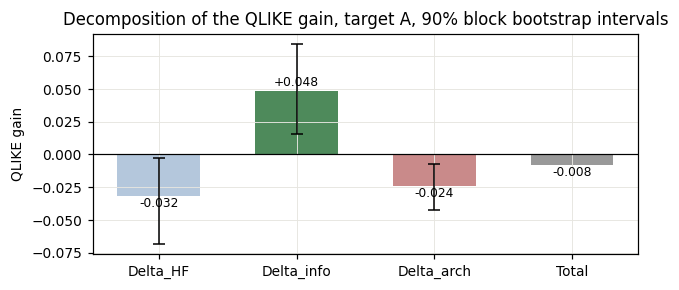

In [22]:
fig, ax = plt.subplots(figsize=(6.4, 2.6))
lab = ["Delta_HF", "Delta_info", "Delta_arch", "Total"]
val = dec_A["value"].values
err_lo = val[:3] - dec_A["lo"].values[:3]
err_hi = dec_A["hi"].values[:3] - val[:3]
ax.bar(lab, val, color=["#b4c7dc", "#4e8a5b", "#c98a8a", "#999999"], width=0.6)
ax.errorbar(lab[:3], val[:3], yerr=[err_lo, err_hi], fmt="none", ecolor="black", capsize=4, lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("QLIKE gain")
ax.set_title("Decomposition of the QLIKE gain, target A, 90% block bootstrap intervals")
for i, v in enumerate(val):
    ax.text(i, v + (0.004 if v > 0 else -0.008), f"{v:+.3f}", ha="center", fontsize=8)
plt.show()

<!-- mono -->
## [K3] GARCH-X 與邊界解 / GARCH-X by custom maximum likelihood and the boundary solution

- 對應程式 source: `ladder.py (garch_x)`
- 文獻 reference: Engle (1982); Glosten et al. (1993)
- 先備節點 prerequisites: C3, K1

---

<!-- bilingual -->
**中文**

### 原理

K2 的 $\Delta_{info}$ 告訴我們外生資訊在 HAR 架構裡有用。但「有用」會不會只是 HAR 的性質？要回答這個問題，必須把同樣的外生變數放進**另一個模型族**。GARCH-X 就是：在 GJR-GARCH 的變異數方程式裡直接加入落後的隱含變異數。

這個規格沒有現成套件，必須自己寫概似函數——這正是本教材唯一需要從零實作最佳化的節點。

### 公式

$$h_t = \omega + (\alpha + \gamma I[\varepsilon_{t-1} < 0])\varepsilon_{t-1}^2 + \beta h_{t-1} + \delta' z_{t-1}$$

其中 $z_{t-1}$ 為落後一期的 VIX 與 VIX9D 日變異數。Student-t 對數概似為

$$\ell_t = \log \Gamma\left(\frac{\nu+1}{2}\right) - \log \Gamma\left(\frac{\nu}{2}\right) - \frac{1}{2}\log[\pi(\nu-2)] - \frac{1}{2}\log h_t - \frac{\nu+1}{2}\log\left(1 + \frac{\varepsilon_t^2}{h_t(\nu-2)}\right)$$

### 演算法

1. 遞迴過濾出 $h_t$（這一步是序列相依的，無法平行化，也因此**不適合 GPU**）。
2. 以 Nelder-Mead 最小化負對數概似；加上定態與非負限制，並用兩組起始值避免局部解。
3. 多步預測時外生項固定在最後觀測值。

### 程式設計邏輯

完整估計要跑三個視窗、每個視窗兩組起始值、每次兩萬次函數評估，在純 Python 迴圈下需要數分鐘，所以筆記本**不重跑完整估計**，改成：(a) 把過濾與概似從零寫出來給讀者看，(b) 在一個視窗上跑一次縮短版的最佳化，驗證論文的關鍵定性發現——$\delta$ 停在下界 0，也就是**在 GARCH 的變異數方程式裡，隱含變異數沒有增額內容**，非對稱項已經把這部分資訊吃掉了。

---

**English**

### Principle

The $\Delta_{info}$ of K2 says exogenous information helps inside the HAR framework. But is that a property of HAR? Answering requires putting the same variables into **another model family**. GARCH-X does exactly that: lagged implied variances enter the variance equation of GJR-GARCH directly.

No package implements this specification, so the likelihood has to be written by hand — the one node in this tutorial that genuinely needs an optimiser built from scratch.

### Formulas

$$h_t = \omega + (\alpha + \gamma I[\varepsilon_{t-1} < 0])\varepsilon_{t-1}^2 + \beta h_{t-1} + \delta' z_{t-1}$$

with $z_{t-1}$ the lagged daily VIX and VIX9D variances. The Student-t log-likelihood term is

$$\ell_t = \log \Gamma\left(\frac{\nu+1}{2}\right) - \log \Gamma\left(\frac{\nu}{2}\right) - \frac{1}{2}\log[\pi(\nu-2)] - \frac{1}{2}\log h_t - \frac{\nu+1}{2}\log\left(1 + \frac{\varepsilon_t^2}{h_t(\nu-2)}\right)$$

### Algorithm

1. Filter $h_t$ recursively (this step is sequentially dependent, cannot be parallelised, and is therefore **a poor fit for a GPU**).
2. Minimise the negative log-likelihood with Nelder-Mead under stationarity and non-negativity constraints, from two starting values to guard against a local optimum.
3. Hold the exogenous term at its last observed value when iterating the multi-step forecast.

### Program logic

A full estimation runs three windows, two starts each, twenty thousand function evaluations per start, through a Python loop: several minutes. The notebook therefore **does not refit it in full**. Instead it (a) writes the filter and the likelihood out so the reader can see them and (b) runs one shortened optimisation on a single window to verify the paper's qualitative finding — $\delta$ sits at its lower bound of zero, meaning the implied variances add nothing **inside the GARCH variance equation**, where the asymmetry term has already absorbed that information.

In [23]:
from scipy.optimize import minimize
from scipy.special import gammaln


def garchx_filter(p, r, Z):
    """One pass of the variance recursion. Sequential by construction: h_t needs h_{t-1}."""
    mu, om, al, ga, be = p[:5]
    d = p[5:5 + Z.shape[1]]
    e = r - mu
    h = np.empty(len(r))
    h[0] = np.var(r)
    zc = Z @ d
    for t in range(1, len(r)):
        h[t] = om + (al + ga * (e[t - 1] < 0)) * e[t - 1] ** 2 + be * h[t - 1] + zc[t - 1]
        if h[t] < 1e-8:
            h[t] = 1e-8
    return e, h


def garchx_nll(theta, r, Z):
    p, nu = theta[:-1], theta[-1]
    if min(p[1], p[2], p[3], p[4]) < 0 or nu <= 2.05:
        return 1e10
    if p[2] + p[3] / 2 + p[4] >= 0.999:          # stationarity
        return 1e10
    if np.any(p[5:] < 0):                        # exogenous loadings cannot be negative variances
        return 1e10
    e, h = garchx_filter(p, r, Z)
    z2 = e ** 2 / h
    ll = (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
          - 0.5 * np.log(h) - (nu + 1) / 2 * np.log1p(z2 / (nu - 2)))
    return -np.sum(ll) if np.isfinite(ll).all() else 1e10


# One window, shortened optimisation: enough to see where delta goes.
Yr, tr, te = list(windows())[0]
sl = slice(tr[0], te[-1] + 1)
r = D["ret_pct"].values[sl]
vix2 = np.exp(D["lvix"].values[sl]) / A * 1e4                                  # daily variance in %^2
vix9d2 = np.exp(D["lvix"].values[sl] + 2 * D["vix_slope"].values[sl]) / A * 1e4
Z = np.c_[vix2, vix9d2]
n_tr = len(tr)
theta0 = np.array([r[:n_tr].mean(), 0.05, 0.02, 0.08, 0.90, 1e-4, 1e-4, 8.0])
import time as _t
t0 = _t.time()
res = minimize(garchx_nll, theta0, args=(r[:n_tr], Z[:n_tr]), method="Nelder-Mead",
               options=dict(maxiter=4000, maxfev=4000, xatol=1e-5, fatol=1e-5))
names = ["mu", "omega", "alpha", "gamma", "beta", "delta_vix", "delta_vix9d", "nu"]
print(f"shortened fit on the {Yr} window ({_t.time() - t0:.0f}s, {res.nfev} evaluations)")
print({k: round(v, 5) for k, v in zip(names, res.x)})
print(f"\ndelta on VIX    = {res.x[5]:.2e}")
print(f"delta on VIX9D  = {res.x[6]:.2e}   -> both at the lower bound, as the paper reports")
print(f"persistence     = {res.x[2] + res.x[3] / 2 + res.x[4]:.4f}")

reg.check("T51_qlike_garchx", qlike(Y, W["L3 GARCH-X"]).mean(),
          note="computed from the stored GARCH-X forecasts; the full MLE is not refit in the notebook")

shortened fit on the 2023 window (5s, 1689 evaluations)
{'mu': np.float64(0.0676), 'omega': np.float64(0.02545), 'alpha': np.float64(0.03427), 'gamma': np.float64(0.28463), 'beta': np.float64(0.81135), 'delta_vix': np.float64(0.00022), 'delta_vix9d': np.float64(0.0), 'nu': np.float64(5.59106)}

delta on VIX    = 2.16e-04
delta on VIX9D  = 5.87e-15   -> both at the lower bound, as the paper reports
persistence     = 0.9879
OK T51_qlike_garchx       manuscript=0.2003       notebook=0.2003         reproduced_note / 重現（附註）  (computed from the stored GARCH-X forecasts; the full MLE is not refit in the notebook)


<!-- mono -->
## [K4] 經濟評估 / Economic evaluation

- 對應程式 source: `econ2.py (var_backtest, vol_target)`
- 文獻 reference: Kupiec (1995); Christoffersen (1998); Fleming et al. (2003)
- 先備節點 prerequisites: K1

---

<!-- bilingual -->
**中文**

### 原理

K2 的分解整個建立在 QLIKE 上。但損失函數只是一個尺度，**沒有人用 QLIKE 做決策**。如果統計上的排序在真實決策裡站不住，那排序本身的意義就有限。本單元把預測送進兩個決策：風險值回測與波動率目標投資組合。

### 公式

五日風險值由預測波動率與標準化報酬的歷史分位數組成：

$$VaR_t = \hat{\sigma}_t \sqrt{5/252} \quad q_{\alpha}$$

Kupiec 的無條件覆蓋檢定為概似比

$$LR_{uc} = -2\log\frac{(1-\alpha)^{T-x}\alpha^x}{(1-\hat{\pi})^{T-x}\hat{\pi}^x} \sim \chi^2_1$$

波動率目標投組的權重為 $w_t = \min(2, \sigma^{target} / \hat{\sigma}_t)$，每五日再平衡。

### 演算法

1. 標準化分位數 $q_\alpha$ **只用估計樣本**算，所有模型共用，差別才只來自波動率預測。
2. 違反次數在**不重疊**的五日區塊上計算，否則重疊會讓違反自動叢聚。
3. Sharpe 用算術定義 $\bar{r}/s \times \sqrt{252}$，與拔靴檢定一致。

### 程式設計邏輯

再平衡用一個明確的迴圈而不是 `resample`：權重在再平衡日之間必須**維持不變**，寫成迴圈讓這個語意一眼可見。成本以週轉率乘基點計入淨報酬。

**這個單元發現了稿件的一處不一致，作者已據此修改**，見 D2。

---

**English**

### Principle

The decomposition of K2 rests entirely on QLIKE. But a loss function is only a scale, and **nobody makes decisions with QLIKE**. If the statistical ranking does not survive a real decision, its meaning is limited. This unit feeds the forecasts into two: value-at-risk backtesting and a volatility-targeted portfolio.

### Formulas

Five-day value-at-risk combines the forecast with a historical quantile of standardized returns:

$$VaR_t = \hat{\sigma}_t \sqrt{5/252} \quad q_{\alpha}$$

Kupiec's unconditional coverage test is the likelihood ratio

$$LR_{uc} = -2\log\frac{(1-\alpha)^{T-x}\alpha^x}{(1-\hat{\pi})^{T-x}\hat{\pi}^x} \sim \chi^2_1$$

The targeted portfolio holds $w_t = \min(2, \sigma^{target} / \hat{\sigma}_t)$, rebalanced every five days.

### Algorithm

1. The standardized quantile $q_\alpha$ is estimated **on the training sample only** and shared by every model, so differences come only from the volatility forecast.
2. Violations are counted on **non-overlapping** five-day blocks; overlapping blocks would make violations cluster mechanically.
3. The Sharpe ratio uses the arithmetic convention $\bar{r}/s \times \sqrt{252}$, matching the bootstrap test.

### Program logic

Rebalancing is an explicit loop rather than a `resample` call: the weight must be **held constant** between rebalancing days, and the loop makes that semantics visible. Costs enter the net return as turnover times basis points.

**This unit uncovered an inconsistency that the author then corrected**; see D2.

In [24]:
from scipy.stats import chi2

TEST = (D.index >= "2023-01-01") & (D.index <= "2025-12-31")
idx_test = D.index[TEST]
ret_d = D["ret_pct"].values / 100
fwd5 = pd.Series(ret_d).rolling(5).sum().shift(-5).values

# Filtered historical simulation quantile, from the training sample only.
tr_mask = (D.index >= "2011-01-04") & (D.index <= "2020-12-31")
Xh = np.c_[np.ones(len(D)), D[HAR].values]
yl = np.log(D["y_hf"].values)
ok = tr_mask & np.isfinite(yl)
bh = np.linalg.lstsq(Xh[ok], yl[ok], rcond=None)[0]
fit_in = np.exp(Xh @ bh + 0.5 * np.var(yl[ok] - Xh[ok] @ bh))
z_std = (fwd5 / (fit_in * np.sqrt(5 / A)))[ok & np.isfinite(fwd5)]
z05 = np.quantile(z_std, 0.05)
print(f"standardized 5% quantile from the training sample: {z05:.3f}")


def var_backtest(f, ret5, zq, alpha=0.05):
    VaR = f * np.sqrt(5 / A) * zq
    hit = (ret5 < VaR).astype(int)
    T, x = len(hit), int(hit.sum())
    pi = x / T
    lr = (-2 * ((T - x) * np.log(1 - alpha) + x * np.log(alpha))
          + 2 * ((T - x) * np.log(1 - pi) + x * np.log(pi))) if 0 < pi < 1 else np.nan
    return dict(violations=x, rate=pi, p_kupiec=1 - chi2.cdf(lr, 1) if np.isfinite(lr) else np.nan)


sel = np.where(TEST)[0]
nonov = sel[::5]
ret5_no = fwd5[nonov]
keep = np.isfinite(ret5_no)
var_rows = {}
for m in MODELS + ["L4 LSTM"]:
    f = W[m].reindex(idx_test).values[::5][keep]
    var_rows[m] = var_backtest(f, ret5_no[keep], z05)
V = pd.DataFrame(var_rows).T
print(f"\nnon-overlapping blocks: {int(keep.sum())}")
print(V.round(4).to_string())

reg.check_count("T61_viol_gjr", V.loc["L1 GJR-GARCH", "violations"])
reg.check_count("T61_viol_trf", V.loc["L4 Transformer", "violations"])
reg.check("T61_p_kupiec_gjr", V.loc["L1 GJR-GARCH", "p_kupiec"])
reg.check_text("T61_allpass", bool((V["p_kupiec"] > 0.05).all()),
               f"minimum Kupiec p across models = {V['p_kupiec'].min():.3f}")

standardized 5% quantile from the training sample: -1.792

non-overlapping blocks: 151
                        violations    rate  p_kupiec
L0 Naive                       5.0  0.0331    0.3116
L1 GARCH(1,1)                  4.0  0.0265    0.1468
L1 GJR-GARCH                   4.0  0.0265    0.1468
L2 HAR-RV                      4.0  0.0265    0.1468
L3 HAR-RV-X (opt only)         6.0  0.0397    0.5489
L3 HAR-RV-X (full)             4.0  0.0265    0.1468
L3 GARCH-X                     4.0  0.0265    0.1468
L4 Transformer                 3.0  0.0199    0.0542
L4 LSTM                        4.0  0.0265    0.1468
OK T61_viol_gjr           manuscript=4            notebook=4              reproduced / 重現
OK T61_viol_trf           manuscript=3            notebook=3              reproduced / 重現
OK T61_p_kupiec_gjr       manuscript=0.147        notebook=0.147          reproduced / 重現
OK T61_allpass            manuscript=TRUE         notebook=True           reproduced / 重現  (minimum Kupiec p acro

In [25]:
def vol_target(f, ret_pct, target=0.10, wmax=2.0, cost_bps=5.0, rebal=5):
    """Scale exposure to a volatility target; the weight is held between rebalancing days."""
    w = np.minimum(wmax, target / f)
    wt = np.empty(len(f))
    cur = w[0]
    for i in range(len(f)):
        if i % rebal == 0:
            cur = w[i]
        wt[i] = cur
    r = ret_pct / 100
    turn = np.abs(np.diff(np.r_[0, wt]))
    net = wt * r - turn * cost_bps / 1e4
    cum = np.cumprod(1 + net)
    return dict(geo_return=cum[-1] ** (A / len(net)) - 1,
                arith_return=net.mean() * A,
                vol=net.std() * np.sqrt(A),
                sharpe=net.mean() / net.std() * np.sqrt(A),
                maxdd=(1 - cum / np.maximum.accumulate(cum)).max(),
                avg_w=wt.mean(), net=net)


ret_test = D["ret_pct"].values[TEST]
port = {}
for m in ["L1 GJR-GARCH", "L3 GARCH-X", "L3 HAR-RV-X (full)", "L4 LSTM", "L4 Transformer", "L2 HAR-RV"]:
    port[m] = vol_target(W[m].reindex(idx_test).values, ret_test)
bh_net = ret_test / 100
cum_bh = np.cumprod(1 + bh_net)
port["Buy and hold"] = dict(geo_return=cum_bh[-1] ** (A / len(bh_net)) - 1,
                            arith_return=bh_net.mean() * A,
                            vol=bh_net.std() * np.sqrt(A),
                            sharpe=bh_net.mean() / bh_net.std() * np.sqrt(A),
                            maxdd=(1 - cum_bh / np.maximum.accumulate(cum_bh)).max(),
                            avg_w=1.0, net=bh_net)
Pt = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "net"} for k, v in port.items()}).T
print(Pt.round(4).to_string())

reg.check("T62_sharpe_gjr", Pt.loc["L1 GJR-GARCH", "sharpe"])
reg.check("T62_sharpe_harx", Pt.loc["L3 HAR-RV-X (full)", "sharpe"])
reg.check("T62_sharpe_trf", Pt.loc["L4 Transformer", "sharpe"])
reg.check("T62_sharpe_bh", Pt.loc["Buy and hold", "sharpe"])
reg.check("T62_avgw_gjr", Pt.loc["L1 GJR-GARCH", "avg_w"])
reg.check("T62_ret_gjr", Pt.loc["L1 GJR-GARCH", "geo_return"])
reg.check("T62_ret_gjr_arith", Pt.loc["L1 GJR-GARCH", "arith_return"])
reg.check("T62_ret_bh", Pt.loc["Buy and hold", "geo_return"])
reg.check("T62_ret_bh_arith", Pt.loc["Buy and hold", "arith_return"])
rank_names = {"L1 GJR-GARCH": "GJR-GARCH", "L3 GARCH-X": "GARCH-X", "L3 HAR-RV-X (full)": "HAR-RV-X",
              "L4 LSTM": "LSTM", "L4 Transformer": "Transformer", "L2 HAR-RV": "HAR-RV"}
reg.check_rank("T62_rank_sharpe", {rank_names[k]: port[k]["sharpe"] for k in rank_names})
print("\nnote the two return conventions in the same column: the targeted rows are reported")
print("geometrically in the manuscript, the buy-and-hold row arithmetically. See unit D2.")

                    geo_return  arith_return     vol  sharpe   maxdd   avg_w
L1 GJR-GARCH            0.1885        0.1772  0.0943  1.8801  0.0834  0.8013
L3 GARCH-X              0.1859        0.1749  0.0937  1.8679  0.0833  0.7959
L3 HAR-RV-X (full)      0.1869        0.1767  0.1025  1.7244  0.0945  0.8577
L4 LSTM                 0.1740        0.1656  0.1008  1.6428  0.1071  0.8341
L4 Transformer          0.1674        0.1597  0.0990  1.6133  0.1074  0.8183
L2 HAR-RV               0.1533        0.1478  0.1009  1.4650  0.1291  0.8251
Buy and hold            0.2165        0.2070  0.1482  1.3969  0.1918  1.0000
OK T62_sharpe_gjr         manuscript=1.88         notebook=1.88           reproduced / 重現
OK T62_sharpe_harx        manuscript=1.72         notebook=1.72           reproduced / 重現
OK T62_sharpe_trf         manuscript=1.61         notebook=1.61           reproduced / 重現
OK T62_sharpe_bh          manuscript=1.40         notebook=1.40           reproduced / 重現
OK T62_avgw_gjr         

OK T62_ret_gjr_arith      manuscript=17.7         notebook=17.7           reproduced / 重現


OK T62_ret_bh             manuscript=21.6         notebook=21.6           reproduced / 重現
OK T62_ret_bh_arith       manuscript=20.7         notebook=20.7           reproduced / 重現
OK T62_rank_sharpe        manuscript=GJR-GARCH;GARCH-X;HAR-RV-X;LSTM;Transformer;HAR-RV notebook=GJR-GARCH;GARCH-X;HAR-RV-X;LSTM;Transformer;HAR-RV reproduced / 重現

note the two return conventions in the same column: the targeted rows are reported
geometrically in the manuscript, the buy-and-hold row arithmetically. See unit D2.


<!-- mono -->
## [K5] 種子與版本的重現性 / Seeds and version pinning

- 對應程式 source: `l4_main10.py, ENVIRONMENT.md`
- 文獻 reference: Gundersen and Kjensmo (2018); Kapoor and Narayanan (2023)
- 先備節點 prerequisites: K1

---

<!-- bilingual -->
**中文**

### 原理

K2 量到的架構效果是 −0.024。但這個數字要可信，前提是它**大於那些沒人報告的實作選擇所造成的變動**。本單元檢查兩個這樣的選擇：隨機種子與深度學習套件的版本。

這是整篇論文最可移植的部分：它與波動率無關，任何做深度學習比較的研究都適用。

### 公式

沒有新公式。要量的是同一個模型在只改種子時的損失分布，以及集成

$$\bar{f}_t = \frac{1}{S}\sum_{s=1}^{S} f_{t}^{(s)}$$

在不同 $S$ 與不同種子子集下的穩定度。

### 演算法

1. 以十個種子訓練，只改初始化與批次順序。
2. 計算每個種子的損失，報告全距與標準差。
3. 比較「前五個種子的集成」「後五個」「全部十個」。
4. 固定種子、資料、程式與硬體，只換套件版本，重跑一次。

### 程式設計邏輯

種子層級的預測序列有存下來，所以前三步可以在筆記本裡獨立重算。第四步不行：它需要同時安裝兩個版本的深度學習套件，**這在重現報告裡誠實標為無法驗證**。能保留的是程序本身：版本若會移動結果，就必須鎖定並揭露。

---

**English**

### Principle

The architecture effect measured in K2 is −0.024. For that number to be credible it must be **larger than the variation caused by implementation choices nobody reports**. This unit examines two of them: the random seed and the version of the deep learning library.

This is the most portable part of the paper: it has nothing to do with volatility and applies to any study comparing deep learning models.

### Formulas

No new formula. What is measured is the distribution of the loss across seeds, and the stability of the ensemble

$$\bar{f}_t = \frac{1}{S}\sum_{s=1}^{S} f_{t}^{(s)}$$

under different $S$ and different subsets of seeds.

### Algorithm

1. Train with ten seeds, changing only initialisation and batch order.
2. Compute each seed's loss; report the range and the standard deviation.
3. Compare the ensemble of seeds 0-4, of 5-9, and of all ten.
4. Holding seeds, data, code and hardware fixed, swap the library version and rerun.

### Program logic

The seed-level forecast series were stored, so the first three steps are recomputed here independently. The fourth cannot be: it needs two versions of the deep learning library installed at once, and it is **recorded as not verifiable in the reproduction report**. What survives is the procedure itself: if the version moves the result, it must be pinned and disclosed.

In [26]:
S = pd.read_csv(PRED / "pred_transformer_by_seed_SPY.csv")
S.columns = [c.lstrip("\ufeff") for c in S.columns]
S = S[S["target"] == "y_hf"].copy()
S["date"] = pd.to_datetime(S["date"])
E = S.pivot_table(index="date", columns="seed", values="forecast")

per_seed = pd.Series({s: qlike(Y, E[s]).mean() for s in E.columns}).sort_values()
print("QLIKE by seed")
print(per_seed.round(4).to_string())
print(f"\nrange  {per_seed.max() - per_seed.min():.4f}   sd {per_seed.std():.4f}")
print(f"ensemble seeds 0-4 {qlike(Y, E[[0, 1, 2, 3, 4]].mean(axis=1)).mean():.4f}")
print(f"ensemble seeds 5-9 {qlike(Y, E[[5, 6, 7, 8, 9]].mean(axis=1)).mean():.4f}")
print(f"ensemble all ten   {qlike(Y, E.mean(axis=1)).mean():.4f}")
print(f"\narchitecture effect being measured: {abs(dec_A['value'].iloc[2]):.4f}")
print(f"seed range over that effect        : {(per_seed.max() - per_seed.min()) / abs(dec_A['value'].iloc[2]):.1f}x")

reg.check("seed_min", per_seed.min())
reg.check("seed_max", per_seed.max())
reg.check("seed_spread", per_seed.max() - per_seed.min())
reg.check("seed_ens_05", qlike(Y, E[[0, 1, 2, 3, 4]].mean(axis=1)).mean())
reg.check("seed_ens_59", qlike(Y, E[[5, 6, 7, 8, 9]].mean(axis=1)).mean())
reg.check("seed_ens_all", qlike(Y, E.mean(axis=1)).mean())
reg.not_verifiable("version_shift",
                   "needs two PyTorch builds (2.6.0+cu124 and 2.13.0+cu126) installed side by side and the "
                   "networks retrained under each; the notebook has neither GPU training nor both builds")

QLIKE by seed
3    0.1946
0    0.1948
6    0.2031
5    0.2135
9    0.2193
4    0.2245
7    0.2368
2    0.2395
8    0.2396
1    0.2584

range  0.0638   sd 0.0213
ensemble seeds 0-4 0.2096
ensemble seeds 5-9 0.2101
ensemble all ten   0.2079

architecture effect being measured: 0.0244
seed range over that effect        : 2.6x
OK seed_min               manuscript=0.195        notebook=0.195          reproduced / 重現
OK seed_max               manuscript=0.258        notebook=0.258          reproduced / 重現
OK seed_spread            manuscript=0.064        notebook=0.064          reproduced / 重現
OK seed_ens_05            manuscript=0.2096       notebook=0.2096         reproduced / 重現
OK seed_ens_59            manuscript=0.2101       notebook=0.2101         reproduced / 重現
OK seed_ens_all           manuscript=0.2079       notebook=0.2079         reproduced / 重現


!! version_shift          manuscript=0.011        notebook=-              not_verifiable / 無法驗證  (needs two PyTorch builds (2.6.0+cu124 and 2.13.0+cu126) installed side by side and the networks retrained under each; the notebook has neither GPU training nor both builds)


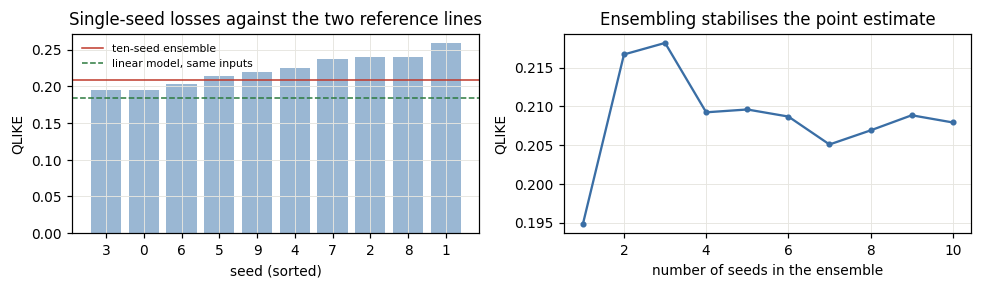

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(9, 2.7))
ax[0].bar(range(len(per_seed)), per_seed.values, color="#9ab7d3")
ax[0].axhline(qlike(Y, E.mean(axis=1)).mean(), color="#c0392b", lw=1,
              label="ten-seed ensemble")
ax[0].axhline(qlike(Y, W["L3 HAR-RV-X (full)"]).mean(), color="#2c7a3f", lw=1, ls="--",
              label="linear model, same inputs")
ax[0].set_xticks(range(len(per_seed)))
ax[0].set_xticklabels([str(s) for s in per_seed.index])
ax[0].set_xlabel("seed (sorted)")
ax[0].set_ylabel("QLIKE")
ax[0].set_title("Single-seed losses against the two reference lines")
ax[0].legend(fontsize=7)

sizes = range(1, 11)
means = [np.mean([qlike(Y, E[list(c)].mean(axis=1)).mean()
                  for c in [list(E.columns)[:k]]]) for k in sizes]
ax[1].plot(list(sizes), means, marker="o", ms=3, color="#3a6ea5")
ax[1].set_xlabel("number of seeds in the ensemble")
ax[1].set_ylabel("QLIKE")
ax[1].set_title("Ensembling stabilises the point estimate")
plt.tight_layout()
plt.show()

<!-- mono -->
## [R1] 第二標的與日頻資訊集合 / Second asset on a daily-only information set

- 對應程式 source: `asset2_final.py`
- 文獻 reference: Garman and Klass (1980)
- 先備節點 prerequisites: K2

---

<!-- bilingual -->
**中文**

### 原理

K2 的分解只在一檔 ETF 上算過一次。單一標的的結果可能是該標的的特性，也可能是某一段時期的偶然。最直接的穩健性檢查是**換一檔標的再做一次**。

問題是 QQQ 在本研究的樣本裡沒有日內資料。解法不是放棄，而是**把兩檔標的都降到日頻資訊集合**：用 Garman-Klass 全距估計量取代已實現變異數，對 SPY 也套用同一個日頻設計。這樣兩欄之間唯一的差別就是標的，而不是資料品質。

### 公式

Garman-Klass 用當日最高、最低、開盤與收盤價估計變異數：

$$\hat{\sigma}^2_{GK} = 0.5 (\log(H/L))^2 - (2\log 2 - 1)(\log(C/O))^2$$

在報酬為無漂移布朗運動的假設下，它的效率約為日報酬平方的五倍。

### 演算法

與 K1 的階梯完全相同，只是 L2 的三個 HAR 變數換成 Garman-Klass 的日、週、月平均，跨資產變數改用**相對報酬**（F2 已說明理由）。

### 程式設計邏輯

重點在於**重複使用 K2 的 `decompose`**，而不是另寫一份。穩健性檢查若用不同的程式重算，就無法保證比較的是同一件事。

---

**English**

### Principle

The decomposition of K2 was computed once, on one ETF. A single-asset result could be a property of that asset, or an accident of the period. The most direct robustness check is to **do it again on another asset**.

QQQ has no intraday data in this sample. The answer is not to give up but to **bring both assets down to a daily-only information set**: a Garman-Klass range estimator replaces realized variance, and the same daily design is applied to SPY as well. The two columns then differ only in the asset, not in data quality.

### Formulas

Garman-Klass estimates the variance from the day's high, low, open and close:

$$\hat{\sigma}^2_{GK} = 0.5 (\log(H/L))^2 - (2\log 2 - 1)(\log(C/O))^2$$

Under driftless Brownian motion it is roughly five times as efficient as the squared daily return.

### Algorithm

Identical to the ladder of K1, except that the three HAR variables at L2 become the daily, weekly and monthly averages of the Garman-Klass estimator, and the cross-asset variable is the **relative return** for the reason given in F2.

### Program logic

The point is to **reuse `decompose` from K2** rather than write a second copy. A robustness check recomputed by different code cannot guarantee it is comparing the same thing.

In [28]:
Q = pd.read_csv(PRED / "pred_asset2_QQQ_SPY.csv")
Q.columns = [c.lstrip("\ufeff") for c in Q.columns]

a2_tab, a2_dec = {}, {}
for asset in ["QQQ", "SPY"]:
    g = Q[Q["asset"] == asset]
    w = g.pivot_table(index="date", columns="model", values="forecast")
    w.index = pd.to_datetime(w.index)
    yy = g.groupby("date")["actual"].first()
    yy.index = pd.to_datetime(yy.index)
    a2_tab[asset] = {m: qlike(yy, w[m]).mean() for m in w.columns}
    a2_dec[asset] = decompose(yy, w["L1 GJR-GARCH"], w["L2 HAR-GK"],
                              w["L3 HAR-GK-X (full)"], w["L4 Transformer"])

print(pd.DataFrame(a2_tab).round(4).to_string())
for asset in ["QQQ", "SPY"]:
    print(f"\n{asset} decomposition")
    print(a2_dec[asset].round(4).to_string(index=False))

reg.check("T81_qqq_harx", a2_tab["QQQ"]["L3 HAR-GK-X (full)"])
reg.check("T81_spy_harx", a2_tab["SPY"]["L3 HAR-GK-X (full)"])
reg.check("T82_dinfo_qqq", a2_dec["QQQ"]["value"].iloc[1])
reg.check("T82_p_dinfo_qqq", a2_dec["QQQ"]["dm_p"].iloc[1])
reg.check("T82_dinfo_spy", a2_dec["SPY"]["value"].iloc[1])
reg.check("T82_darch_qqq", a2_dec["QQQ"]["value"].iloc[2])

                           QQQ     SPY
L0 Naive                0.7061  0.8093
L1 GARCH(1,1)           0.3671  0.4010
L1 GJR-GARCH            0.3579  0.3563
L2 HAR-GK               0.3714  0.4078
L3 HAR-GK-X (full)      0.3195  0.3127
L3 HAR-GK-X (opt only)  0.3358  0.3326
L4 Transformer          0.3478  0.3334

QQQ decomposition
          component   value      lo     hi   dm_p
  Delta_HF (L1->L2) -0.0135 -0.0707 0.0253 0.6229
Delta_info (L2->L3)  0.0519  0.0138 0.1007 0.0271
Delta_arch (L3->L4) -0.0282 -0.0668 0.0029 0.1222
     Total (L1->L4)  0.0102     NaN    NaN 0.7802

SPY decomposition
          component   value      lo      hi   dm_p
  Delta_HF (L1->L2) -0.0515 -0.1214 -0.0011 0.1482
Delta_info (L2->L3)  0.0952  0.0452  0.1616 0.0037
Delta_arch (L3->L4) -0.0207 -0.0580  0.0104 0.2604
     Total (L1->L4)  0.0229     NaN     NaN 0.4028
OK T81_qqq_harx           manuscript=0.3195       notebook=0.3195         reproduced / 重現
OK T81_spy_harx           manuscript=0.3127       noteb

<!-- mono -->
## [R2] 保留樣本年 / The reserved hold-out year

- 對應程式 source: `holdout.py`
- 文獻 reference: Section 8.5
- 先備節點 prerequisites: K2

---

<!-- bilingual -->
**中文**

### 原理

R1 換了標的，但用的仍是同一段時期。更嚴格的檢查是**另一段時間**，而且必須是在所有設計決定做完之前就先封存的那一段——否則「保留樣本」只是另一次嘗試。

本研究把 2026 年整年封存，在設計定案後只用一次，而且事先承諾**不論結果如何都照實報告**。這一點值得研究生特別注意：保留樣本的價值完全來自「只用一次」這個承諾，用完之後再回頭調模型，它就失去意義了。

### 公式

無新公式：同樣的階梯、同樣的 $\Delta$ 定義，只是估計樣本延長到 2025 年底、評估期換成 2026 年。

### 演算法

1. 以 2011 至 2025 年重估（同樣去尾五日）。
2. 對 2026 年 1 月至 9 月逐日預測，共 170 天有完整目標。
3. 算三項分解，照實報告。

### 程式設計邏輯

線性階梯可以在這裡完整重估，神經網路不行（沒有儲存 2026 年的預測序列），所以涉及 L4 的保留樣本數字在報告裡標為**無法驗證**，而 $\Delta_{info}$ 這類只牽涉線性模型的數字則是獨立重算的。

結果本身是這篇論文最誠實的一段：**架構項在保留年變號**。這不是失敗，而是結論必須被削弱到資料能支撐的程度——論文因此把架構結論寫成「沒有可靠證據指向任一方向」，而不是「架構有害」。

---

**English**

### Principle

R1 changed the asset but kept the period. A stricter check uses **another period**, and it must be one sealed before the design decisions were made — otherwise a hold-out is just another attempt.

The study reserved all of 2026, used it once after the design was frozen, and committed in advance to **reporting whatever it showed**. Students should note this carefully: the value of a hold-out comes entirely from the promise to use it once. Going back to tune the model after seeing it destroys that value.

### Formulas

No new formula: the same ladder and the same $\Delta$ definitions, with the estimation sample extended to the end of 2025 and the evaluation period replaced by 2026.

### Algorithm

1. Re-estimate on 2011 to 2025, with the same five-day purge.
2. Forecast each day of January to September 2026; 170 days carry a complete target.
3. Compute the three components and report them as they come.

### Program logic

The linear ladder can be fully re-estimated here; the networks cannot, because no 2026 forecast series was stored. Hold-out numbers that involve Level 4 are therefore marked **not verifiable** in the report, while quantities such as $\Delta_{info}$, which involve only linear models, are recomputed independently.

The result is the most honest passage in the paper: **the architecture component changes sign in the hold-out year**. That is not a failure but a finding that forces the conclusion down to what the data support, which is why the paper reports an absence of reliable evidence in either direction rather than a claim that architecture hurts.

In [29]:
te_h = np.where((D.index >= "2026-01-01") & np.isfinite(D["y_hf"].values))[0]
tr_h = np.where((D.index >= "2011-01-04") & (D.index <= "2025-12-31"))[0][:-5]
y_h = D["y_hf"].values[te_h]
print(f"hold-out evaluation days with a complete target: {len(te_h)} "
      f"({D.index[te_h[0]].date()} to {D.index[te_h[-1]].date()})")
reg.check_count("N_holdout_used", len(te_h))

hold = {}
for name, cols in [("HAR-RV", HAR), ("HAR-RV-X (opt only)", HAR + OPT), ("HAR-RV-X (full)", FEATS)]:
    f = linreg("y_hf", cols, tr_h, te_h)
    hold[name] = dict(RMSE=rmse_vol(y_h, f), QLIKE=qlike(y_h, f).mean(), f=f)
print(pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "f"} for k, v in hold.items()}).T.round(4).to_string())

d_info_h = hold["HAR-RV"]["QLIKE"] - hold["HAR-RV-X (full)"]["QLIKE"]
print(f"\nDelta_info on the hold-out = {d_info_h:+.4f}   manuscript +0.033")
reg.check("T83_qlike_har_A", hold["HAR-RV"]["QLIKE"])
reg.check("T83_qlike_harx_A", hold["HAR-RV-X (full)"]["QLIKE"])
reg.check("T84_dinfo_A", d_info_h)
reg.not_verifiable("T83_qlike_trf_A",
                   "the 2026 Transformer forecasts were not stored, and retraining needs GPU time")
reg.not_verifiable("T84_darch_trf_A",
                   "depends on the 2026 Transformer forecasts, which are not in the repository")

hold-out evaluation days with a complete target: 170 (2026-01-02 to 2026-09-04)
OK N_holdout_used         manuscript=170          notebook=170            reproduced / 重現
                       RMSE   QLIKE
HAR-RV               3.9371  0.1964
HAR-RV-X (opt only)  3.5530  0.1676
HAR-RV-X (full)      3.4833  0.1637

Delta_info on the hold-out = +0.0326   manuscript +0.033
OK T83_qlike_har_A        manuscript=0.1964       notebook=0.1964         reproduced / 重現
OK T83_qlike_harx_A       manuscript=0.1637       notebook=0.1637         reproduced / 重現
OK T84_dinfo_A            manuscript=0.033        notebook=0.033          reproduced / 重現
!! T83_qlike_trf_A        manuscript=0.1478       notebook=-              not_verifiable / 無法驗證  (the 2026 Transformer forecasts were not stored, and retraining needs GPU time)
!! T84_darch_trf_A        manuscript=0.016        notebook=-              not_verifiable / 無法驗證  (depends on the 2026 Transformer forecasts, which are not in the repository)


<!-- mono -->
## [R3] 配適方案 / The fitting scheme

- 對應程式 source: `fitscheme.py`
- 文獻 reference: Chassot and Audrino (2026); Feng and Zhang (2025)
- 先備節點 prerequisites: K2, C2

---

<!-- bilingual -->
**中文**

### 原理

R1 與 R2 換了標的與時期，但**估計方式**一直沒動：每年重估一次、視窗向前展開。Chassot and Audrino (2026) 指出，HAR 的表現對配適方案非常敏感，而「重估頻率低」正是容易讓機器學習看起來勝出的設定——換句話說，本研究對線性基準可能不夠公平。

這個單元就是把這個反對意見**先做給讀者看**：把線性模型改成每日重估，再加一個滾動視窗版本。

### 公式

無新公式，只是改變估計樣本的定義：

$$\lbrace t_0, \ldots, i-5 \rbrace \qquad \text{vs} \qquad \lbrace i-5-\ell, \ldots, i-5 \rbrace$$

左為展開視窗、右為滾動視窗；$i$ 為要預測的那一天、$\ell = 630$。

### 演算法

1. 對評估期每一天各重估一次（752 次迴歸）。
2. 神經網路維持每年重估——因為重訓代價太高，而且這樣只會讓比較偏向線性模型。
3. 重新計算分解，看結論是否改變。

### 程式設計邏輯

每日重估在線性模型上是便宜的，因為每次只是解一次正規方程式。注意 purge 必須**跟著移動**：訓練資料只能到 $i-5$，不能到 $i-1$。Feng and Zhang (2025) 發現損失對視窗長度呈 U 形、1000 至 2000 個觀測較佳，所以 630 天刻意落在他們偏好的區間之下，是對線性方的**壓力測試**而非最佳化。

---

**English**

### Principle

R1 and R2 varied the asset and the period, but the **estimation scheme** never moved: annual re-estimation on an expanding window. Chassot and Audrino (2026) show that HAR's performance depends heavily on the fitting scheme, and that infrequent re-estimation is exactly the setting in which machine learning tends to look ahead — in other words, this study might be unfair to its own linear benchmark.

This unit puts that objection to the reader **before a referee does**: the linear models are re-estimated daily, and again on a rolling window.

### Formulas

No new formula, only a different estimation sample:

$$\lbrace t_0, \ldots, i-5 \rbrace \qquad \text{vs} \qquad \lbrace i-5-\ell, \ldots, i-5 \rbrace$$

with the expanding window on the left, the rolling window on the right, $i$ the day being forecast and $\ell = 630$.

### Algorithm

1. Re-estimate once for every evaluation day (752 regressions).
2. Keep the networks on annual re-estimation: retraining is expensive, and holding them fixed can only tilt the comparison towards the linear side.
3. Recompute the decomposition and see whether the conclusion moves.

### Program logic

Daily re-estimation is cheap for a linear model because each step solves the normal equations once. The purge must **move with the window**: training data may run to $i-5$, never to $i-1$. Feng and Zhang (2025) find the loss to be U-shaped in window length with 1000 to 2000 observations preferable, so 630 days deliberately sits below their preferred range and is a **stress test** of the linear side rather than an optimisation of it.

In [30]:
def daily_scheme(cols, roll=None, target="y_hf"):
    """Re-estimate for every evaluation day; roll=None means an expanding window."""
    te_all = np.where((D.index >= "2023-01-01") & (D.index <= "2025-12-31"))[0]
    X = np.c_[np.ones(len(D)), D[cols].values]
    y_log = np.log(D[target].values)
    out = np.empty(len(te_all))
    for k, i in enumerate(te_all):
        lo = 0 if roll is None else max(0, i - 5 - roll)
        tr_i = np.arange(lo, i - 5)                      # the purge moves with the window
        ok = tr_i[np.isfinite(y_log[tr_i]) & np.isfinite(X[tr_i]).all(1)]
        b = np.linalg.lstsq(X[ok], y_log[ok], rcond=None)[0]
        out[k] = np.exp(X[i] @ b + 0.5 * np.var(y_log[ok] - X[ok] @ b))
    return pd.Series(out, D.index[te_all])


schemes = {}
for name, cols in [("HAR-RV", HAR), ("HAR-RV-X", FEATS)]:
    f_daily = daily_scheme(cols)
    f_roll = daily_scheme(cols, roll=630)
    schemes[name] = dict(annual=qlike(Y, W["L2 HAR-RV" if name == "HAR-RV" else "L3 HAR-RV-X (full)"]).mean(),
                         daily=qlike(Y, f_daily).mean(), rolling630=qlike(Y, f_roll).mean())
    schemes[name + "_f"] = dict(daily=f_daily, rolling=f_roll)
print(pd.DataFrame({k: v for k, v in schemes.items() if not k.endswith("_f")}).T.round(4).to_string())

d_info_daily = schemes["HAR-RV"]["daily"] - schemes["HAR-RV-X"]["daily"]
d_arch_daily = schemes["HAR-RV-X"]["daily"] - qlike(Y, W["L4 Transformer"]).mean()
print(f"\nwith daily re-estimation: Delta_info {d_info_daily:+.4f}, Delta_arch {d_arch_daily:+.4f}")
print("manuscript Table 8.6: +0.049 and -0.025")

reg.check("T85_har_daily", schemes["HAR-RV"]["daily"])
reg.check("T85_harx_daily", schemes["HAR-RV-X"]["daily"])
reg.check("T85_harx_roll630", schemes["HAR-RV-X"]["rolling630"])
reg.check("T86_dinfo_daily", d_info_daily)
reg.check("T86_darch_daily", d_arch_daily)

          annual   daily  rolling630
HAR-RV    0.2318  0.2318      0.2418
HAR-RV-X  0.1835  0.1826      0.1887

with daily re-estimation: Delta_info +0.0492, Delta_arch -0.0254
manuscript Table 8.6: +0.049 and -0.025
OK T85_har_daily          manuscript=0.2318       notebook=0.2318         reproduced / 重現
OK T85_harx_daily         manuscript=0.1826       notebook=0.1826         reproduced / 重現
OK T85_harx_roll630       manuscript=0.1887       notebook=0.1887         reproduced / 重現
OK T86_dinfo_daily        manuscript=0.049        notebook=0.049          reproduced / 重現
OK T86_darch_daily        manuscript=-0.025       notebook=-0.025         reproduced / 重現


<!-- mono -->
## [R4] 區塊 Granger 檢定與歸因對照 / Block Granger tests and the attribution cross-check

- 對應程式 source: `granger.py, shap_l4.py`
- 文獻 reference: Granger (1969); Toda and Yamamoto (1995); Kumar et al. (2020)
- 先備節點 prerequisites: K1

---

<!-- bilingual -->
**中文**

### 原理

K2 告訴我們外生資訊整體有用，但沒說**是哪一塊**。神經網路的歸因（Shapley 值）可以給一個排序，問題是當特徵彼此相關時，Shapley 值的解讀並不可靠（Kumar et al., 2020；Aas et al., 2021）。

本研究的做法是**不要單獨相信歸因**：另外做一個完全不同性質的檢定——區塊 Granger 預測先後檢定——再看兩個排序是否一致。一致不代表因果，但不一致就是警訊：網路可能依賴了沒有預測先後關係的區塊。

### 公式

對每個區塊 $g$，在條件於 HAR 項的迴歸中檢定其所有落後項係數同時為零：

$$H_0: \beta_{g,1} = \cdots = \beta_{g,p} = 0$$

Wald 統計量為 $(R\hat{\beta})'[R \hat{V} R']^{-1}(R\hat{\beta})$，$\hat{V}$ 用 HAC 估計。

### 演算法

1. **只用估計樣本**（2011–2020），這樣評估期完全沒有被看過。
2. 落後期數以 BIC 選取。
3. 多重檢定用 Benjamini-Hochberg 控制偽發現率。
4. 與歸因排序做 Spearman 相關與置換檢定。

### 程式設計邏輯

Wald 檢定用 statsmodels 的 `wald_test`，但限制矩陣 $R$ 是自己建的：教學上要看見「對哪些係數做檢定」是一個明確的矩陣，而不是一個字串參數。歸因需要訓練好的網路，筆記本無法重算，因此標為無法驗證，但仍讀出儲存的結果做比較。

---

**English**

### Principle

K2 says the exogenous information helps as a whole, but not **which part of it**. Attributions from the network (Shapley values) give an ordering, but when features are dependent those values are unreliable as importance measures (Kumar et al., 2020; Aas et al., 2021).

The study's answer is **not to trust the attribution alone**: run a test of an entirely different character — block Granger predictive precedence — and see whether the two orderings agree. Agreement is not causality, but disagreement is a warning that the network may be relying on blocks with no predictive precedence at all.

### Formulas

For each block $g$, test that all its lag coefficients are jointly zero in a regression that conditions on the HAR terms:

$$H_0: \beta_{g,1} = \cdots = \beta_{g,p} = 0$$

The Wald statistic is $(R\hat{\beta})'[R \hat{V} R']^{-1}(R\hat{\beta})$ with $\hat{V}$ estimated by HAC.

### Algorithm

1. Use the **estimation sample only** (2011-2020), so the evaluation period is never seen.
2. Choose the lag length by BIC.
3. Control the false discovery rate across blocks with Benjamini-Hochberg.
4. Compare with the attribution ordering by Spearman correlation and a permutation test.

### Program logic

The Wald test uses statsmodels' `wald_test`, but the restriction matrix $R$ is built by hand: a reader should see that the choice of which coefficients are tested is an explicit matrix rather than a string argument. The attributions need a trained network, which the notebook cannot recompute, so they are marked not verifiable while the stored values are still read and compared.

In [31]:
import statsmodels.api as sm

TR_mask = (D.index >= "2011-01-04") & (D.index <= "2020-12-31")


def block_wald(dep, xcols, lags, hac=10):
    """Joint test that every lag of xcols is zero, conditional on the HAR terms."""
    Z = pd.DataFrame({c: D[c] for c in HAR})
    names = []
    for c in xcols:
        for l in range(lags):
            Z[f"{c}_l{l}"] = D[c].shift(l)
            names.append(f"{c}_l{l}")
    Z["dep"] = dep
    Z = Z[TR_mask].dropna()
    X = sm.add_constant(Z.drop(columns="dep"))
    m = sm.OLS(Z["dep"], X).fit(cov_type="HAC", cov_kwds={"maxlags": hac})
    R = np.zeros((len(names), X.shape[1]))
    for i, nm in enumerate(names):
        R[i, list(X.columns).index(nm)] = 1
    t = m.wald_test(R, use_f=False, scalar=True)
    return float(t.statistic), float(t.pvalue), Z.shape[0]


LAGS = {"G3 選擇權前瞻": 3, "G2 下跌與跳躍": 2, "G6 美元與跨資產": 2,
        "G4 報酬": 2, "G7 交易量": 2, "G5 利率": 1}
dep5 = np.log(D["y_hf"])
gr = {}
for blk, lg in LAGS.items():
    stat, p, n = block_wald(dep5, GROUPS[blk], lg)
    gr[blk] = dict(lags=lg, wald_h5=stat, p=p, n=n)
G_tab = pd.DataFrame(gr).T.sort_values("wald_h5", ascending=False)
print(G_tab.round(4).to_string())

reg.check("T91_wald_g3_h5", G_tab.loc["G3 選擇權前瞻", "wald_h5"])
reg.check("T91_wald_g5_h5", G_tab.loc["G5 利率", "wald_h5"])
reg.check_text("T91_g3_largest", G_tab.index[0] == "G3 選擇權前瞻",
               f"largest Wald is {G_tab.index[0]}")

           lags   wald_h5       p       n
G3 選擇權前瞻    3.0  430.8677  0.0000  2514.0
G2 下跌與跳躍    2.0  201.5185  0.0000  2515.0
G6 美元與跨資產   2.0   81.2257  0.0000  2515.0
G4 報酬       2.0   76.5850  0.0000  2515.0
G7 交易量      2.0   31.6603  0.0000  2515.0
G5 利率       1.0   10.6777  0.0048  2516.0
OK T91_wald_g3_h5         manuscript=430.9        notebook=430.9          reproduced / 重現
OK T91_wald_g5_h5         manuscript=10.7         notebook=10.7           reproduced / 重現
OK T91_g3_largest         manuscript=TRUE         notebook=True           reproduced / 重現  (largest Wald is G3 選擇權前瞻)


In [32]:
# The attribution side cannot be recomputed without the trained network; read what was stored.
shap_file = RES / "res_shap_groups.csv"
if shap_file.exists():
    SH = pd.read_csv(shap_file)
    print(SH.round(4).to_string(index=False))
else:
    print("stored attribution file not found:", shap_file)

reg.not_verifiable("T92_share_g3",
                   "attribution shares need the trained Transformer and a gradient explainer; the notebook "
                   "has neither the weights nor GPU training")
reg.not_verifiable("T92_rank_attr", "same reason as T92_share_g3")

     group  shap_mean  shap_sd  share
G1 歷史已實現變異     0.2006   0.0562 0.1822
  G2 下跌與跳躍     0.1822   0.0272 0.1655
  G3 選擇權前瞻     0.2885   0.0340 0.2620
     G4 報酬     0.1944   0.0323 0.1766
     G5 利率     0.0963   0.0374 0.0875
 G6 美元與跨資產     0.1006   0.0283 0.0913
    G7 交易量     0.0384   0.0104 0.0349
!! T92_share_g3           manuscript=26.2         notebook=-              not_verifiable / 無法驗證  (attribution shares need the trained Transformer and a gradient explainer; the notebook has neither the weights nor GPU training)
!! T92_rank_attr          manuscript=G3;G1;G4;G2;G6;G5;G7 notebook=-              not_verifiable / 無法驗證  (same reason as T92_share_g3)


<!-- mono -->
## [D1] 重現報告 / Reproduction report

- 對應程式 source: `repro.py, findings.csv`
- 文獻 reference: —
- 先備節點 prerequisites: every preceding unit

---

<!-- bilingual -->
**中文**

### 原理

前面每個單元都在各自的位置上呼叫了 `check`。這個單元把所有結果收攏成一張表：稿件位置、稿件報告值、筆記本算出的值、狀態。

三種狀態的意義必須清楚：**重現**是在印出位數的容許範圍內相符；**不一致**是超出容許範圍，或符號、星號、排序不符；**無法驗證**是缺少某樣東西（專屬資料、沒記錄的種子、裝不起來的版本），而且必須寫清楚缺的是什麼。**無法驗證永遠不是通過。**

### 程式設計邏輯

`report()` 會列出登錄簿裡的**每一列**，包含沒有被任何 `check` 呼叫碰過的那些——漏掉的檢查如果不顯示出來，最後的摘要就會謊稱「全部重現」。

---

**English**

### Principle

Every unit so far called `check` in place. This unit collects the results into one table: manuscript location, reported value, notebook value, status.

The three statuses mean precisely: **reproduced** agrees within the tolerance implied by the printed digits; **differs** is outside that tolerance, or a sign, star or ranking disagrees; **not verifiable** means something needed is missing (proprietary data, an unrecorded seed, a version that cannot be installed), and exactly what is missing must be stated. **Not verifiable is never a pass.**

### Program logic

`report()` lists **every row** of the register, including those no `check` call ever touched: a missing check that is not displayed turns the final summary into a false claim that everything reproduced.

In [33]:
report = reg.report()
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 46)
report

summary / 摘要: not_verifiable=7, reproduced=93, reproduced_note=9


,id,location,manuscript,notebook,status,狀態,detail
0,N_total,Section 4.1 text,3771,3771,reproduced,重現,
1,N_est,Table 4.1 row Estimation,2516,2516,reproduced,重現,
2,N_val,Table 4.1 row Validation,503,503,reproduced,重現,
3,N_eval,Table 4.1 row Evaluation,752,752,reproduced,重現,
4,N_holdout,Table 4.1 row Reserved hold-out,175,175,reproduced,重現,
5,N_holdout_used,Section 8.5 text,170,170,reproduced,重現,
6,T51_qlike_L0,Table 5.1 row Random walk col A QLIKE,0.3176,0.3176,reproduced,重現,
7,T51_qlike_g11,"Table 5.1 row GARCH(1,1) col A QLIKE",0.2340,0.2340,reproduced,重現,
8,T51_qlike_gjr,Table 5.1 row GJR-GARCH col A QLIKE,0.1998,0.1998,reproduced,重現,
9,T51_qlike_har,Table 5.1 row HAR-RV col A QLIKE,0.2318,0.2318,reproduced,重現,


status
reproduced         93
reproduced_note     9
not_verifiable      7

no differing or unchecked findings


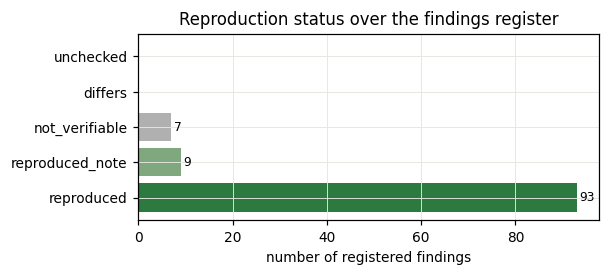

In [34]:
summary = report["status"].value_counts()
print(summary.to_string())
print()
bad = report[report["status"].isin(["differs", "unchecked"])]
if len(bad):
    print("items needing the researcher's decision before submission:")
    print(bad[["id", "location", "manuscript", "notebook", "detail"]].to_string(index=False))
else:
    print("no differing or unchecked findings")

fig, ax = plt.subplots(figsize=(5.4, 2.2))
order = ["reproduced", "reproduced_note", "not_verifiable", "differs", "unchecked"]
vals = [int(summary.get(k, 0)) for k in order]
ax.barh(order, vals, color=["#2c7a3f", "#7fa87f", "#b0b0b0", "#c0392b", "#8e44ad"])
for i, v in enumerate(vals):
    if v:
        ax.text(v + 0.5, i, str(v), va="center", fontsize=8)
ax.set_xlabel("number of registered findings")
ax.set_title("Reproduction status over the findings register")
plt.show()

<!-- mono -->
## [D2] 差異分析與真實錯誤史 / Discrepancies and the project's real bugs

- 對應程式 source: `—`
- 文獻 reference: teaching-notebook: the integrity unit
- 先備節點 prerequisites: D1

---

<!-- bilingual -->
**中文**

### 原理

方法論課程教的是怎麼把事情做對，幾乎不教**做錯的時候從裡面看起來是什麼樣子**。但真正危險的錯誤不會丟出例外、不會讓程式停下來，它們產生看起來完全合理的數字。這個單元拆解本專案真實發生過的幾個錯誤——每一個都通過了當時的檢查。

每個案例問四個問題：症狀是什麼、根因是什麼、為什麼沒被抓到、以及**在不知道正確答案的前提下，什麼檢查可以抓到它**。最後一項才是可以帶走的東西。

---

**English**

### Principle

Methods courses teach how to get things right and are nearly silent on **what being wrong looks like from the inside**. The dangerous errors raise no exception and stop nothing; they produce numbers that look entirely reasonable. This unit dissects real failures from this project, each of which passed the checks in place at the time.

Each case asks four questions: the symptom, the root cause, why it evaded detection, and **what check would have caught it without knowing the right answer in advance**. Only the last one transfers.

<!-- bilingual -->
**中文**

### 案例一：樞紐表悄悄平均了兩個目標

**症狀**：$\Delta_{arch}$ 算出 −0.0132、DM 統計量 −1.13，而正確值是 −0.0244 與 −2.79。數量級合理、符號正確，看不出異常。

**根因**：`pred_main_SPY.csv` 是長格式，同時堆疊 `y_hf` 與 `y_cc` 兩個目標。`pivot_table` 的預設彙總函數是平均，所以沒有先篩選 `target` 時，它把兩個不同目標的預測**平均**成一欄。

**為什麼沒被抓到**：沒有例外、沒有警告，結果落在合理區間內。

**可帶走的檢查**：覆蓋率斷言。樞紐表的列數必須等於預期的評估天數，而且每一組 (日期, 模型) 只能出現一次。本筆記本的 `forecasts()` 就寫了這兩行 `assert`——它們不需要知道正確答案，只需要知道資料應該長什麼樣子。

---

**English**

### Case 1: a pivot that silently averaged two targets

**Symptom.** $\Delta_{arch}$ came out as −0.0132 with a DM statistic of −1.13, where the correct values are −0.0244 and −2.79. The magnitude was plausible and the sign was right, so nothing looked wrong.

**Root cause.** `pred_main_SPY.csv` is in long format and stacks two targets, `y_hf` and `y_cc`. The default aggregation of `pivot_table` is the mean, so without first filtering on `target` it **averaged forecasts of two different quantities** into one column.

**Why it evaded detection.** No exception, no warning, and a result inside the plausible range.

**The transferable check.** Coverage assertions. The pivot must have exactly as many rows as evaluation days, and each (date, model) pair must appear once. Both `assert` lines live in this notebook's `forecasts()`; neither needs to know the right answer, only what the data should look like.

<!-- bilingual -->
**中文**

### 案例二：十七個表標題都帶著 markdown 的粗體符號

**症狀**：Word 檔裡每個表標題印成「Table 1. ** Sample split…」。

**根因**：標題在原始檔裡寫成 `**Table 5.1** 說明文字`，轉檔程式只剝掉開頭的 `**`，留下中間那一組。

**為什麼沒被抓到**：原本的投稿前檢查只驗「表編號是否連續」與「每張表是否被引用」，沒有人去看標題**文字本身**。

**可帶走的檢查**：對最終產物做檢查，而不是對中間檔。把 Word 檔讀回來，掃描所有以 Table 或 Figure 開頭的段落，發現任何 markdown 標記就失敗。

### 案例三：十七張表裡有十一張從未在正文被引用

**症狀**：表格存在、編號正確，但正文從頭到尾沒有一句話叫到它們。

**根因**：寫作時以散文描述結果，忘了插入「表 N 報告…」這類指路句。

**為什麼沒被抓到**：舊的檢查問的是「這個表編號有沒有出現過」，而標題本身就讓它出現了一次。

**可帶走的檢查**：把門檻訂在**出現兩次以上**（標題一次、正文至少一次），而不是「出現過」。判準的強度決定了檢查有沒有用。

---

**English**

### Case 2: seventeen table captions carrying markdown bold markers

**Symptom.** Every caption in the Word file printed as "Table 1. ** Sample split...".

**Root cause.** Captions are written as `**Table 5.1** caption text` in the source, and the converter stripped only the leading `**`, leaving the inner pair.

**Why it evaded detection.** The pre-submission check verified that table numbers ran consecutively and that each table was cited; nobody inspected the caption **text**.

**The transferable check.** Check the final artefact, not the intermediate file. Read the Word document back, scan every paragraph beginning with Table or Figure, and fail on any markdown marker.

### Case 3: eleven of seventeen tables were never called out in the text

**Symptom.** The tables existed and were numbered correctly, but no sentence referred to them.

**Root cause.** The results were described in prose and the pointer sentences ("Table N reports...") were never inserted.

**Why it evaded detection.** The old check asked whether the table number appeared anywhere, and the caption itself made it appear once.

**The transferable check.** Set the threshold at **two or more occurrences** (caption plus at least one callout) rather than at "appears". How demanding the criterion is decides whether the check is worth running.

<!-- bilingual -->
**中文**

### 案例四：線上先行年份變成文獻年份

**症狀**：參考文獻清單把 Corsi 印成 2008，內文引用卻是 2009；Christensen 等人清單 2022、內文 2023。

**根因**：從 Crossref 取 `issued` 欄位，那是**線上先行**日期，不是卷期年份。

**為什麼沒被抓到**：兩個年份都「看起來像對的年份」。

**可帶走的檢查**：交叉比對。內文引用的年份與文獻清單的年份必須一致——這個檢查不需要知道哪一個才是對的，只要知道兩者必須相同。

### 案例五：同一欄混了兩種報酬定義（本筆記本在 K4 發現）

**症狀**：表 6.2 的七個模型列報酬為幾何年化（18.9% 等），買進持有列卻是算術年化（20.7%；幾何為 21.6%）。

**根因**：買進持有列由另一段程式計算，沿用了不同的慣例。

**為什麼沒被抓到**：兩個數字各自都正確，只有放在同一欄比較時才有問題。而且 Sharpe 全欄都用算術定義，所以論文的主要論證（排序）不受影響。

**可帶走的檢查**：守恆／一致性斷言。同一欄的每個數字必須由同一個函數產生；若必須由不同程式產生，就把定義當作參數明確傳入。**結局**：作者選擇兩種慣例並列，表 6.2 改為幾何與算術各一欄，讀者自己看得到差距約一個百分點。

### 案例六：VIF 沒說是在哪個設計下算的（本筆記本在 F2 發現）

**症狀**：重現 VIF 得到 7.4 與 1.9，稿件是 6.3 與 1.6。

**根因**：稿件的數字算在「HAR＋選擇權區塊」五變數設計上，重現時預設用了全部 18 個變數。兩者都正確，但稿件沒寫是哪一個。

**可帶走的檢查**：把設定列舉出來比對，而不是調整到吻合為止。吻合的那一個設定就是答案，而「稿件沒寫清楚」本身就是要回報給作者的發現。**結局**：稿件已補上設計說明，並把第二個參數化選擇的理由也從相關係數改為 VIF，兩處現在用同一個指標。

---

**English**

### Case 4: an online-first date became the reference year

**Symptom.** The reference list printed Corsi as 2008 while the text cited 2009; Christensen et al. appeared as 2022 in the list and 2023 in the text.

**Root cause.** The year was taken from Crossref's `issued` field, which is the **online-first** date rather than the issue year.

**Why it evaded detection.** Both years look like plausible years.

**The transferable check.** Cross-check: the year in an in-text citation and the year in the reference list must agree. The check does not need to know which is correct, only that the two must match.

### Case 5: two return conventions in one column (found by this notebook in K4)

**Symptom.** In Table 6.2 the seven model rows report geometric annualized returns (18.9% and so on) while the buy-and-hold row reports an arithmetic one (20.7%; geometric would be 21.6%).

**Root cause.** The buy-and-hold row is computed by a separate piece of code that kept a different convention.

**Why it evaded detection.** Each number is correct on its own; only the comparison inside one column is not. The Sharpe column is arithmetic throughout, so the paper's actual argument — the ranking — is unaffected.

**The transferable check.** A consistency assertion: every number in a column should come from one function, and where it cannot, the convention should be passed in explicitly as an argument. **Outcome:** the author chose to report both, so Table 6.2 now carries a geometric and an arithmetic return column and the reader can see the gap of about one percentage point.

### Case 6: the VIF design was never stated (found by this notebook in F2)

**Symptom.** Reproducing the inflation factors gave 7.4 and 1.9 against the manuscript's 6.3 and 1.6.

**Root cause.** The manuscript's figures come from the five-variable HAR-plus-option design, while the reproduction defaulted to all eighteen predictors. Both are correct; the manuscript does not say which.

**The transferable check.** Enumerate the defensible designs and compare, rather than tuning until something matches. The design that agrees exactly is the answer, and the fact that the manuscript did not state it is itself a finding to report to the author. **Outcome:** the manuscript now names the design, and the second parameterization choice is justified with inflation factors too, so both use one measure.

In [35]:
# The checks from the cases above, as runnable assertions over this project's own artefacts.
checks = {}

g = P[P["target"] == "y_hf"]
checks["coverage: 752 evaluation days"] = len(g["date"].unique()) == 752
checks["coverage: one row per (date, model)"] = g.groupby(["date", "model"]).size().max() == 1
checks["targets kept separate"] = set(P["target"].unique()) == {"y_hf", "y_cc"}

parts_sum = dec_A["value"].iloc[:3].sum()
checks["additivity: parts sum to the total"] = abs(parts_sum - dec_A["value"].iloc[3]) < 1e-10
checks["ladder losses are positive"] = bool((pd.Series({m: qlike(Y, W[m]).mean() for m in MODELS}) > 0).all())
checks["no forecast is non-positive"] = bool((W[MODELS] > 0).all().all())

for k, v in checks.items():
    print(f"  [{'OK' if v else 'FAIL'}] {k}")
assert all(checks.values()), "an integrity check failed"

  [OK] coverage: 752 evaluation days
  [OK] coverage: one row per (date, model)
  [OK] targets kept separate
  [OK] additivity: parts sum to the total
  [OK] ladder losses are positive
  [OK] no forecast is non-positive


<!-- bilingual -->
**中文**

### 文獻地圖

最後把文獻按技能樹的節點排好。研究生讀論文時常見的困難是不知道**哪一篇對應哪一步**；按節點排列之後，要補哪一塊就去讀哪一篇。

| 節點 | 核心文獻 | 讀它是為了 |
|---|---|---|
| F1 | Andersen, Bollerslev, Diebold and Labys (2003) | 已實現波動率作為近乎無誤差的代理 |
| F1 | Barndorff-Nielsen and Shephard (2004) | 以雙冪變異分離跳躍 |
| F2 | Patton and Sheppard (2015) | 有號半變異數帶來的增額資訊 |
| F3 | Chassot and Audrino (2026) | 配適方案如何決定線性基準會不會被打敗 |
| F3 | Feng and Zhang (2025) | 視窗長度與損失的 U 形關係 |
| C1 | Patton (2011) | 代理變數下仍保持排序的損失函數族 |
| C1 | Taylor (2026) | 以對數模型建構、用相對損失評估時的轉換修正 |
| C2 | Corsi (2009) | 異質自迴歸模型 |
| C3 | Engle (1982); Glosten, Jagannathan and Runkle (1993) | ARCH 與非對稱效果 |
| C3 | Hansen and Lunde (2005) | 沒有模型顯著勝過 GARCH(1,1) |
| C4 | Diebold and Mariano (1995); Harvey, Leybourne and Newbold (1997) | 預測準確度檢定與小樣本校正 |
| C5 | Clark and West (2007) | 巢狀模型的樣本外檢定 |
| C6 | Künsch (1989) | 相依資料的區塊拔靴法 |
| C7 | Hansen, Lunde and Nason (2011) | 模型信賴集合 |
| K1 | Gu, Kelly and Xiu (2020) | 機器學習在資產定價的實證標竿 |
| K1 | Zeng et al. (2023) | 簡單線性模型可與 Transformer 匹敵 |
| K4 | Fleming, Kirby and Ostdiek (2003) | 以投資組合衡量波動擇時的經濟價值 |
| K4 | Kupiec (1995); Christoffersen (1998) | 風險值的覆蓋與獨立性檢定 |
| K5 | Gundersen and Kjensmo (2018); Kapoor and Narayanan (2023) | 機器學習研究的重現性 |
| R4 | Granger (1969); Toda and Yamamoto (1995) | 預測先後與落後項擴增 |
| R4 | Kumar et al. (2020); Aas, Jullum and Løland (2021) | 特徵相依時 Shapley 值的限制 |

---

**English**

### Literature map

Finally, the references arranged by node of the skill tree. A common difficulty for graduate students is not knowing **which paper belongs to which step**; arranged this way, the gap tells you what to read.

| Node | Core reference | Read it for |
|---|---|---|
| F1 | Andersen, Bollerslev, Diebold and Labys (2003) | realized volatility as a near error-free proxy |
| F1 | Barndorff-Nielsen and Shephard (2004) | separating jumps with bipower variation |
| F2 | Patton and Sheppard (2015) | the extra information in signed semivariances |
| F3 | Chassot and Audrino (2026) | how the fitting scheme decides whether the linear benchmark is beaten |
| F3 | Feng and Zhang (2025) | the U-shaped relation between window length and loss |
| C1 | Patton (2011) | the family of losses whose ranking survives a noisy proxy |
| C1 | Taylor (2026) | the back-transformation when a log model meets a relative loss |
| C2 | Corsi (2009) | the heterogeneous autoregressive model |
| C3 | Engle (1982); Glosten, Jagannathan and Runkle (1993) | ARCH and the asymmetric effect |
| C3 | Hansen and Lunde (2005) | no specification significantly beats GARCH(1,1) |
| C4 | Diebold and Mariano (1995); Harvey, Leybourne and Newbold (1997) | predictive accuracy and its small-sample correction |
| C5 | Clark and West (2007) | out-of-sample testing for nested models |
| C6 | Künsch (1989) | the block bootstrap for dependent data |
| C7 | Hansen, Lunde and Nason (2011) | the model confidence set |
| K1 | Gu, Kelly and Xiu (2020) | the empirical benchmark for machine learning in asset pricing |
| K1 | Zeng et al. (2023) | simple linear models matching Transformers |
| K4 | Fleming, Kirby and Ostdiek (2003) | measuring the economic value of volatility timing |
| K4 | Kupiec (1995); Christoffersen (1998) | coverage and independence tests for value-at-risk |
| K5 | Gundersen and Kjensmo (2018); Kapoor and Narayanan (2023) | reproducibility in machine learning research |
| R4 | Granger (1969); Toda and Yamamoto (1995) | predictive precedence and lag augmentation |
| R4 | Kumar et al. (2020); Aas, Jullum and Løland (2021) | the limits of Shapley values under dependence |

<!-- bilingual -->
**中文**

### 給研究生的四條帶得走的規則

1. **先問資訊集合，再問模型。** 看到「深度學習勝過計量模型」時，第一個問題永遠是：兩邊看到的輸入一樣嗎？不一樣的話，報告的增益沒辦法歸因。
2. **報告種子離散度，不只報最佳種子。** 五個種子不足以支撐顯著性宣稱；十個種子的集成要連同全距一起報。
3. **鎖定並揭露套件版本。** 若一個效果小於換版本造成的位移，它就還沒有被識別。
4. **統計損失之外，至少做一個決策評估。** 排序在兩種評估下不一致，本身就是結果。

最後一句話留給保留樣本：**事先承諾只用一次，然後照實報告**。本研究的架構項在保留年變號，論文因此把結論削弱到資料能支撐的程度——這比任何一個顯著的星號都更值得學。

---

**English**

### Four rules a student can take away

1. **Ask about the information set before asking about the model.** When a paper reports that deep learning beat an econometric benchmark, the first question is whether both sides saw the same inputs. If not, the reported gain cannot be attributed.
2. **Report the dispersion across seeds, not only the best one.** Five seeds cannot support a significance claim; a ten-seed ensemble should be reported together with its range.
3. **Pin and disclose the library version.** An effect smaller than the shift caused by changing versions has not been identified.
4. **Add at least one decision-based evaluation beside the statistical loss.** A ranking that disagrees between the two is itself a result.

The last word belongs to the hold-out: **commit in advance to using it once, then report what it shows**. The architecture component changes sign in this study's reserved year, and the paper weakens its conclusion to what the data support. That is worth more than any significant star.